In [2]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100000

df = pd.DataFrame({
    "Age": np.random.randint(18, 70, n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Diet_Type": np.random.choice(["Vegetarian", "Non-Vegetarian", "Vegan"], n),
    "Calories": np.random.normal(2100, 400, n).round(),
    "Protein": np.random.normal(70, 20, n).round(),
    "Vegetable_Intake": np.random.normal(3, 1, n).round(1),
    "Fruit_Intake": np.random.normal(2.5, 1, n).round(1),
    "Dairy_Intake": np.random.normal(2, 1, n).round(1),
    "Water_Intake": np.random.normal(2.5, 0.7, n).round(1),
    "Meal_Frequency": np.random.randint(2, 6, n),
    "BMI": np.random.normal(24, 4, n).round(1),
    "Physical_Activity": np.random.choice(["Low", "Moderate", "High"], n)
})

# Adding missing values
for column in df.columns:
    indexes = np.random.choice(df.index, size=int(n * 0.01), replace=False)
    df.loc[indexes, column] = np.nan

# Adding duplicate rows
duplicate_rows = df.sample(500, random_state=42)
df = pd.concat([df, duplicate_rows], ignore_index=True)

# Adding outliers
indexes = np.random.choice(df.index, 300, replace=False)
df.loc[indexes, "Calories"] = np.random.choice([500, 600, 700, 5500, 6000, 7000], 300)

indexes = np.random.choice(df.index, 300, replace=False)
df.loc[indexes, "Protein"] = np.random.choice([5, 10, 15, 200, 250, 300], 300)

indexes = np.random.choice(df.index, 300, replace=False)
df.loc[indexes, "BMI"] = np.random.choice([10, 12, 14, 40, 45, 50], 300)

indexes = np.random.choice(df.index, 300, replace=False)
df.loc[indexes, "Water_Intake"] = np.random.choice([0.2, 0.3, 0.5, 7, 8, 10], 300)

print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

display(df.head())

df.to_csv("nutritional_mock_data_100000.csv", index=False)

Shape: (100500, 12)

Missing Values:
Age                  1002
Gender               1005
Diet_Type            1006
Calories             1007
Protein              1001
Vegetable_Intake     1002
Fruit_Intake         1002
Dairy_Intake         1001
Water_Intake         1002
Meal_Frequency       1006
BMI                   996
Physical_Activity    1001
dtype: int64

Duplicate Rows: 491


,Age,Gender,Diet_Type,Calories,Protein,Vegetable_Intake,Fruit_Intake,Dairy_Intake,Water_Intake,Meal_Frequency,BMI,Physical_Activity
0,56.0,Female,Non-Vegetarian,2235.0,56.0,3.6,3.0,1.9,3.5,5.0,20.7,Low
1,69.0,Female,Vegetarian,3057.0,62.0,2.6,2.7,2.2,2.0,3.0,25.1,High
2,46.0,Male,Vegan,1210.0,54.0,3.1,0.8,-0.9,2.1,5.0,22.4,Low
3,32.0,Male,Vegan,2538.0,94.0,2.5,1.1,1.4,1.7,3.0,22.9,Low
4,60.0,Male,Non-Vegetarian,1934.0,83.0,2.6,1.8,3.0,1.8,5.0,29.4,High


In [3]:
df["Diet_Type"].unique()

# Preserve original diet detail BEFORE collapsing categories,
# so we can still tell who is Vegan / Vegetarian later (needed for Calcium & B12 risk)
df["Is_Vegan"] = (df["Diet_Type"] == "Vegan").astype(int)
df["Is_Vegetarian"] = (df["Diet_Type"] == "Vegetarian").astype(int)

df["Diet_Type"] = df["Diet_Type"].replace({
    "Vegetarian": "Vegeterian",
    "Vegan": "Veg",
    "Non-Vegetarian": "Non-Veg"
})
df["Diet_Type"]


0            Non-Veg
1         Vegeterian
2                Veg
3                Veg
4            Non-Veg
             ...    
100495    Vegeterian
100496           Veg
100497           Veg
100498       Non-Veg
100499    Vegeterian
Name: Diet_Type, Length: 100500, dtype: str

### 1. Import Libraries

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score

### 2. Load Dataset

In [5]:
# The dataset loading and target column creation has been moved to the EDA section to ensure df is always defined.
print("First 5 rows of the dataset:")
display(df.head())

print("\nShape of the dataset:", df.shape)

print("\nColumns in the dataset:")
print(df.columns.tolist())

print("\nData types of the columns:")
print(df.info())

print("\nMissing values in each column:")
print(df.isnull().sum())

First 5 rows of the dataset:


,Age,Gender,Diet_Type,Calories,Protein,Vegetable_Intake,Fruit_Intake,Dairy_Intake,Water_Intake,Meal_Frequency,BMI,Physical_Activity,Is_Vegan,Is_Vegetarian
0,56.0,Female,Non-Veg,2235.0,56.0,3.6,3.0,1.9,3.5,5.0,20.7,Low,0,0
1,69.0,Female,Vegeterian,3057.0,62.0,2.6,2.7,2.2,2.0,3.0,25.1,High,0,1
2,46.0,Male,Veg,1210.0,54.0,3.1,0.8,-0.9,2.1,5.0,22.4,Low,1,0
3,32.0,Male,Veg,2538.0,94.0,2.5,1.1,1.4,1.7,3.0,22.9,Low,1,0
4,60.0,Male,Non-Veg,1934.0,83.0,2.6,1.8,3.0,1.8,5.0,29.4,High,0,0



Shape of the dataset: (100500, 14)

Columns in the dataset:
['Age', 'Gender', 'Diet_Type', 'Calories', 'Protein', 'Vegetable_Intake', 'Fruit_Intake', 'Dairy_Intake', 'Water_Intake', 'Meal_Frequency', 'BMI', 'Physical_Activity', 'Is_Vegan', 'Is_Vegetarian']

Data types of the columns:
<class 'pandas.DataFrame'>
RangeIndex: 100500 entries, 0 to 100499
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Age                99498 non-null   float64
 1   Gender             99495 non-null   str    
 2   Diet_Type          99494 non-null   str    
 3   Calories           99493 non-null   float64
 4   Protein            99499 non-null   float64
 5   Vegetable_Intake   99498 non-null   float64
 6   Fruit_Intake       99498 non-null   float64
 7   Dairy_Intake       99499 non-null   float64
 8   Water_Intake       99498 non-null   float64
 9   Meal_Frequency     99494 non-null   float64
 10  BMI                99

Humne `nutritional_mock_data_100000.csv` file load kar liya hai. Kyunki is dataset mein deficiency risks nahi the, humne unhein kuch aasan rules se banaya hai. Dataset loading aur target columns banane ka code ab EDA section ke shuru mein move kar diya gaya hai taaki `df` DataFrame hamesha available rahe. Ab hum dataset ki shuruati rows, uska size, columns ke naam, aur har column ke data type aur missing values dekh sakte hain.

### 3. Basic EDA

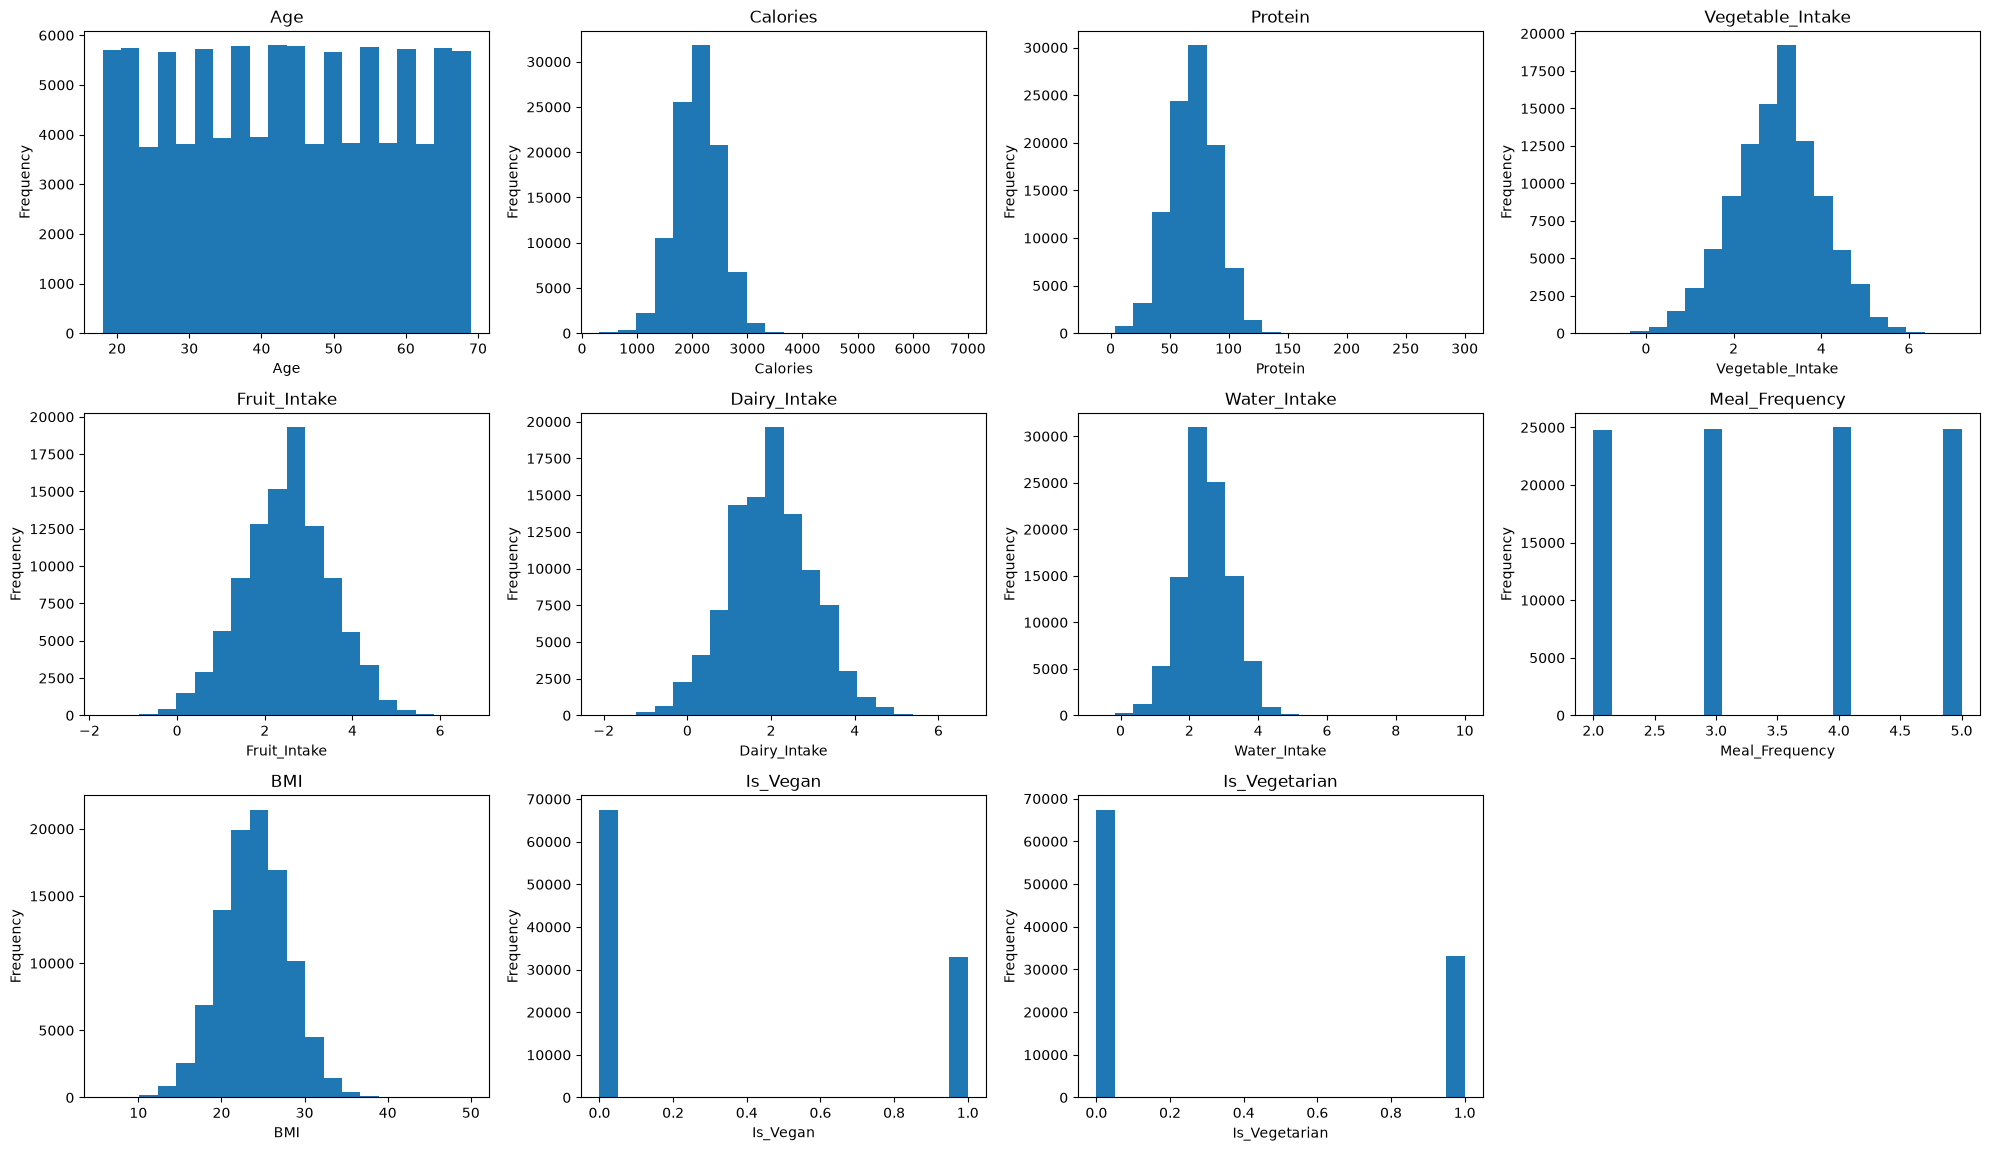

In [6]:
target_columns = [
    'Iron_Deficiency_Risk',
    'Calcium_Deficiency_Risk',
    'Vitamin_D_Deficiency_Risk',
    'Vitamin_B12_Deficiency_Risk'
]

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Target columns ko histograms se remove karna
numerical_cols = [
    col for col in numerical_cols 
    if col not in target_columns
]

plt.figure(figsize=(20, 15))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    plt.hist(df[col].dropna(), bins=20)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [7]:


iron_score = (
    (df['Protein'] < 50).astype(int) +
    (df['Vegetable_Intake'] < 2).astype(int) +
    (df['Calories'] < 1600).astype(int) +
    ((df['Diet_Type'] == 'Veg') | (df['Diet_Type'] == 'Vegan')).astype(int)
)

# 0 = Low, 1-2 = Moderate, 3-4 = High
df['Iron_Deficiency_Risk'] = np.select(
    [
        iron_score >= 2,
        iron_score >= 1
    ],
    [2, 1],
    default=0
)


# ============================================================
# CALCIUM DEFICIENCY RISK
# ============================================================

dairy_points = np.select(
    [
        df['Dairy_Intake'] < 1.0,
        df['Dairy_Intake'] < 2.0
    ],
    [3, 2],
    default=0
)

age_points_calcium = np.select(
    [
        df['Age'] >= 50,
        df['Age'] >= 30
    ],
    [2, 1],
    default=0
)

calcium_score = (
    dairy_points +
    (df['Protein'] < 30).astype(int) +
    (df['Is_Vegan'] == 1).astype(int) * 3 +
    age_points_calcium +
    (df['Gender'] == 'Female').astype(int) * 2 +
    (df['Calories'] < 1000).astype(int) +
    (df['BMI'] < 18.5).astype(int)
)

# 0-2 = Low
# 3-5 = Moderate
# 6+  = High

df['Calcium_Deficiency_Risk'] = np.select(
    [
        calcium_score >= 6,
        calcium_score >= 3
    ],
    [2, 1],
    default=0
)


# ============================================================
# VITAMIN D DEFICIENCY RISK
# ============================================================

vitamin_d_score = (
    (df['Physical_Activity'] == 'Low').astype(int) +
    (df['Dairy_Intake'] < 1.0).astype(int) +
    (df['Dairy_Intake'] < 1.5).astype(int) +
    (df['Age'] >= 50).astype(int) +
    (df['BMI'] >= 30).astype(int)
)

# 0-1 = Low
# 2-3 = Moderate
# 4-5 = High

df['Vitamin_D_Deficiency_Risk'] = np.select(
    [
        vitamin_d_score >= 3,
        vitamin_d_score >= 1
    ],
    [2, 1],
    default=0
)


# ============================================================
# VITAMIN B12 DEFICIENCY RISK
# ============================================================

b12_score = (
    (df['Is_Vegan'] == 1).astype(int) * 3 +
    (df['Is_Vegetarian'] == 1).astype(int) +
    (df['Dairy_Intake'] < 1.0).astype(int) +
    (df['Protein'] < 40).astype(int) +
    (df['Age'] >= 50).astype(int)
)

# 0-1 = Low
# 2-3 = Moderate
# 4+  = High

df['Vitamin_B12_Deficiency_Risk'] = np.select(
    [
        b12_score >= 4,
        b12_score >= 2
    ],
    [2, 1],
    default=0
)


# ============================================================
# CHECK DISTRIBUTION
# ============================================================

print("IRON")
print(df['Iron_Deficiency_Risk'].value_counts().sort_index())

print("\nCALCIUM")
print(df['Calcium_Deficiency_Risk'].value_counts().sort_index())

print("\nVITAMIN D")
print(df['Vitamin_D_Deficiency_Risk'].value_counts().sort_index())

print("\nVITAMIN B12")
print(df['Vitamin_B12_Deficiency_Risk'].value_counts().sort_index())

IRON
Iron_Deficiency_Risk
0    43578
1    42027
2    14895
Name: count, dtype: int64

CALCIUM
Calcium_Deficiency_Risk
0    23302
1    46800
2    30398
Name: count, dtype: int64

VITAMIN D
Vitamin_D_Deficiency_Risk
0    27915
1    60836
2    11749
Name: count, dtype: int64

VITAMIN B12
Vitamin_B12_Deficiency_Risk
0    48118
1    35558
2    16824
Name: count, dtype: int64


In [8]:
for col in [
    'Iron_Deficiency_Risk',
    'Calcium_Deficiency_Risk',
    'Vitamin_D_Deficiency_Risk',
    'Vitamin_B12_Deficiency_Risk'
]:
    print("\n", col)
    print(df[col].value_counts(normalize=True).sort_index() * 100)


 Iron_Deficiency_Risk
Iron_Deficiency_Risk
0    43.361194
1    41.817910
2    14.820896
Name: proportion, dtype: float64

 Calcium_Deficiency_Risk
Calcium_Deficiency_Risk
0    23.186070
1    46.567164
2    30.246766
Name: proportion, dtype: float64

 Vitamin_D_Deficiency_Risk
Vitamin_D_Deficiency_Risk
0    27.776119
1    60.533333
2    11.690547
Name: proportion, dtype: float64

 Vitamin_B12_Deficiency_Risk
Vitamin_B12_Deficiency_Risk
0    47.878607
1    35.381095
2    16.740299
Name: proportion, dtype: float64


In [9]:
target_columns = [
    'Iron_Deficiency_Risk',
    'Calcium_Deficiency_Risk',
    'Vitamin_D_Deficiency_Risk',
    'Vitamin_B12_Deficiency_Risk'
]

for col in target_columns:
    print("\n" + "="*40)
    print(col)
    print(df[col].value_counts())


Iron_Deficiency_Risk
Iron_Deficiency_Risk
0    43578
1    42027
2    14895
Name: count, dtype: int64

Calcium_Deficiency_Risk
Calcium_Deficiency_Risk
1    46800
2    30398
0    23302
Name: count, dtype: int64

Vitamin_D_Deficiency_Risk
Vitamin_D_Deficiency_Risk
1    60836
0    27915
2    11749
Name: count, dtype: int64

Vitamin_B12_Deficiency_Risk
Vitamin_B12_Deficiency_Risk
0    48118
1    35558
2    16824
Name: count, dtype: int64


### Target Distributions

C:\Users\Momo\AppData\Local\Temp\ipykernel_20040\1440189053.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis')
C:\Users\Momo\AppData\Local\Temp\ipykernel_20040\1440189053.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis')
C:\Users\Momo\AppData\Local\Temp\ipykernel_20040\1440189053.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df, palette='viridis')
C:\Users\Momo\AppData\Local\Temp\ipykernel_20040\1440189053.py:6: FutureWarning: 

Passing `palette`

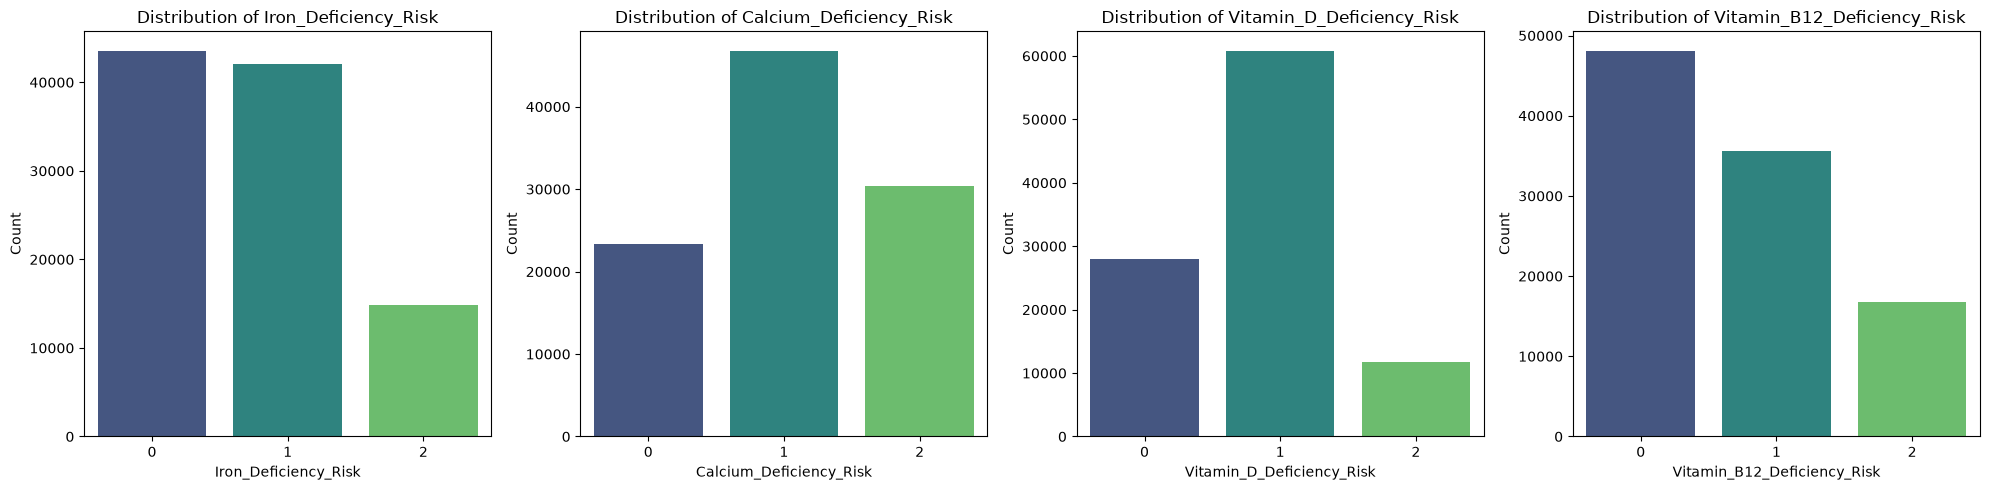

In [10]:
target_columns = ['Iron_Deficiency_Risk', 'Calcium_Deficiency_Risk', 'Vitamin_D_Deficiency_Risk', 'Vitamin_B12_Deficiency_Risk']

plt.figure(figsize=(20, 5))
for i, col in enumerate(target_columns):
    plt.subplot(1, 4, i + 1)
    sns.countplot(x=col, data=df, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Histograms for Numerical Columns

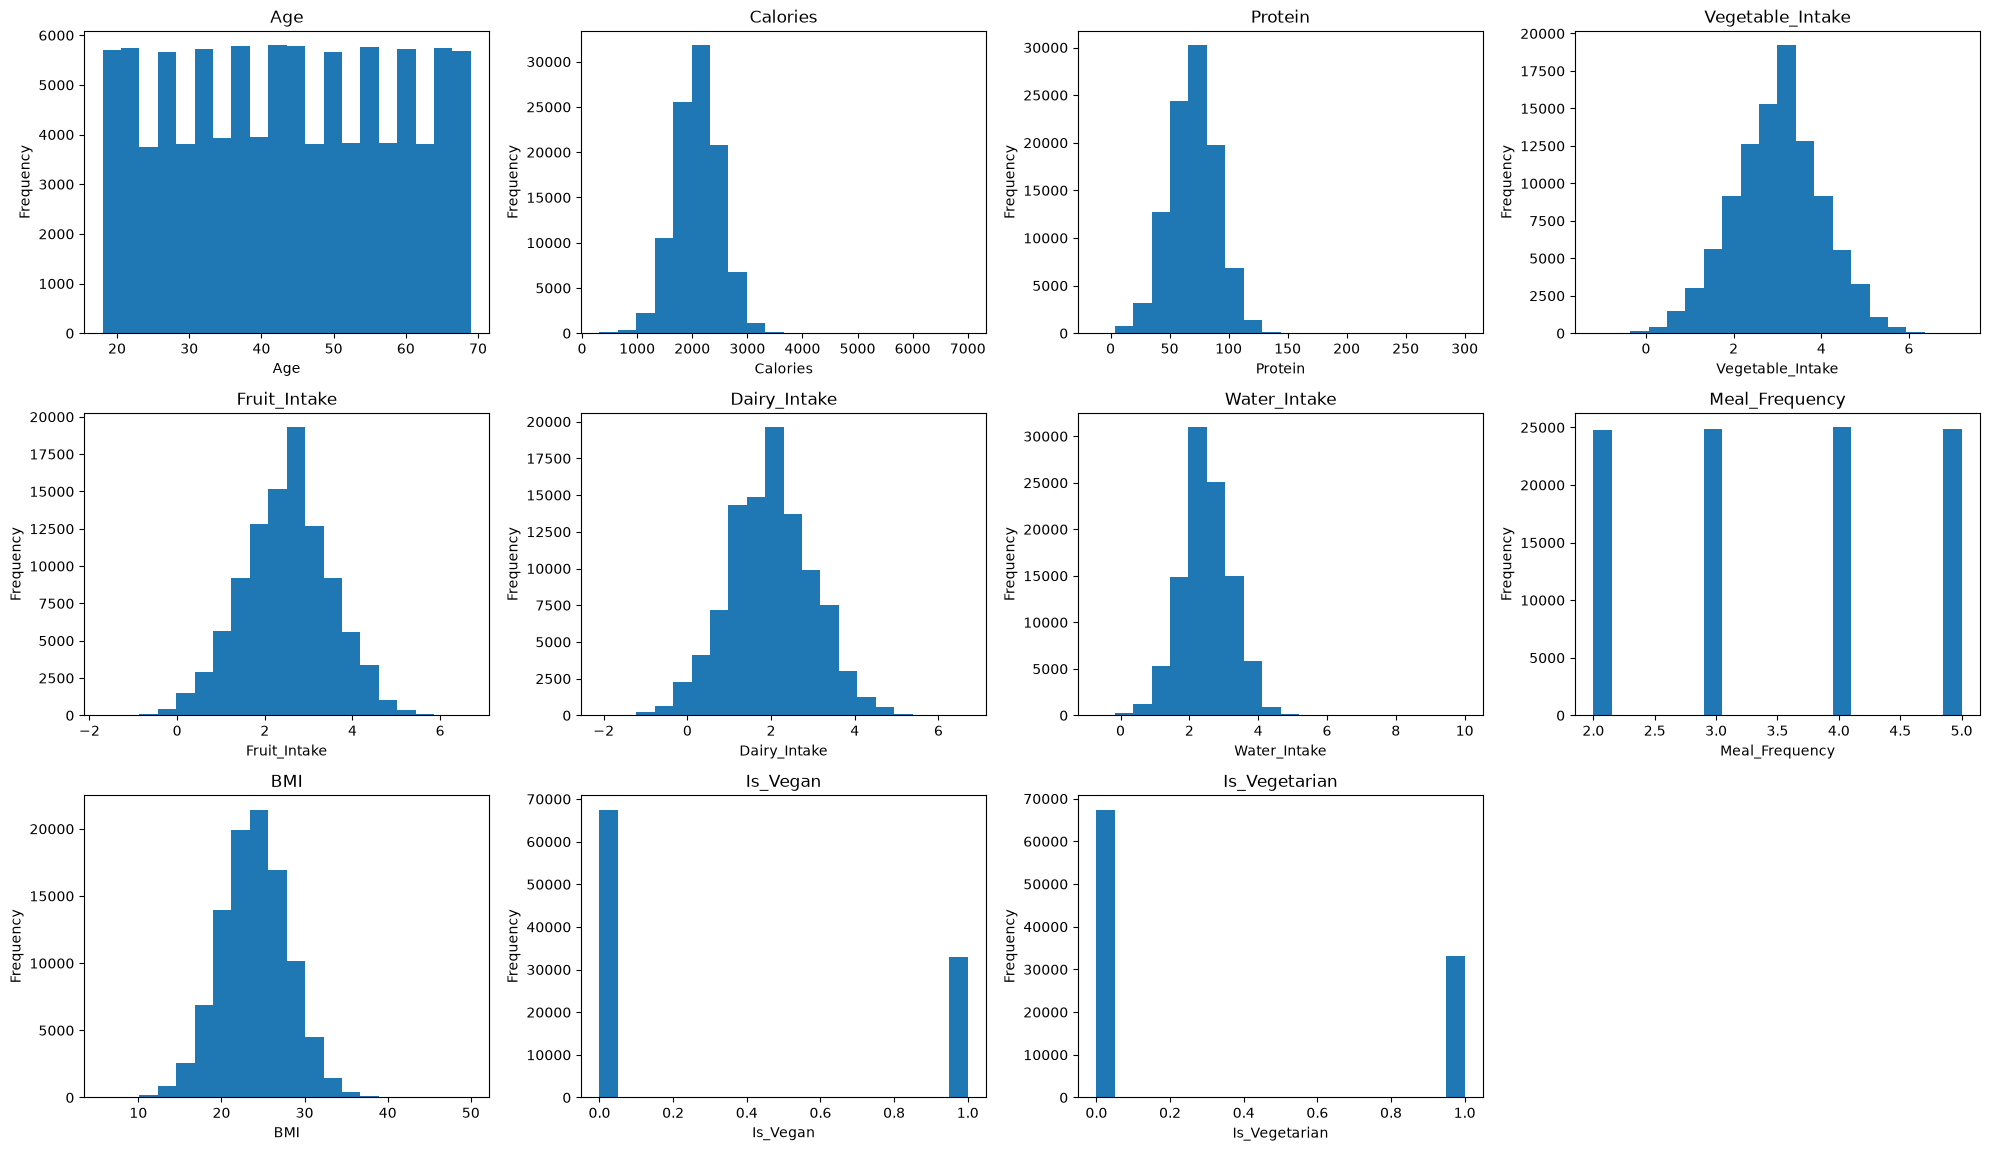

In [11]:
target_columns = [
    'Iron_Deficiency_Risk',
    'Calcium_Deficiency_Risk',
    'Vitamin_D_Deficiency_Risk',
    'Vitamin_B12_Deficiency_Risk'
]

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Target columns ko histograms se remove karna
numerical_cols = [
    col for col in numerical_cols 
    if col not in target_columns
]

plt.figure(figsize=(20, 15))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    plt.hist(df[col].dropna(), bins=20)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

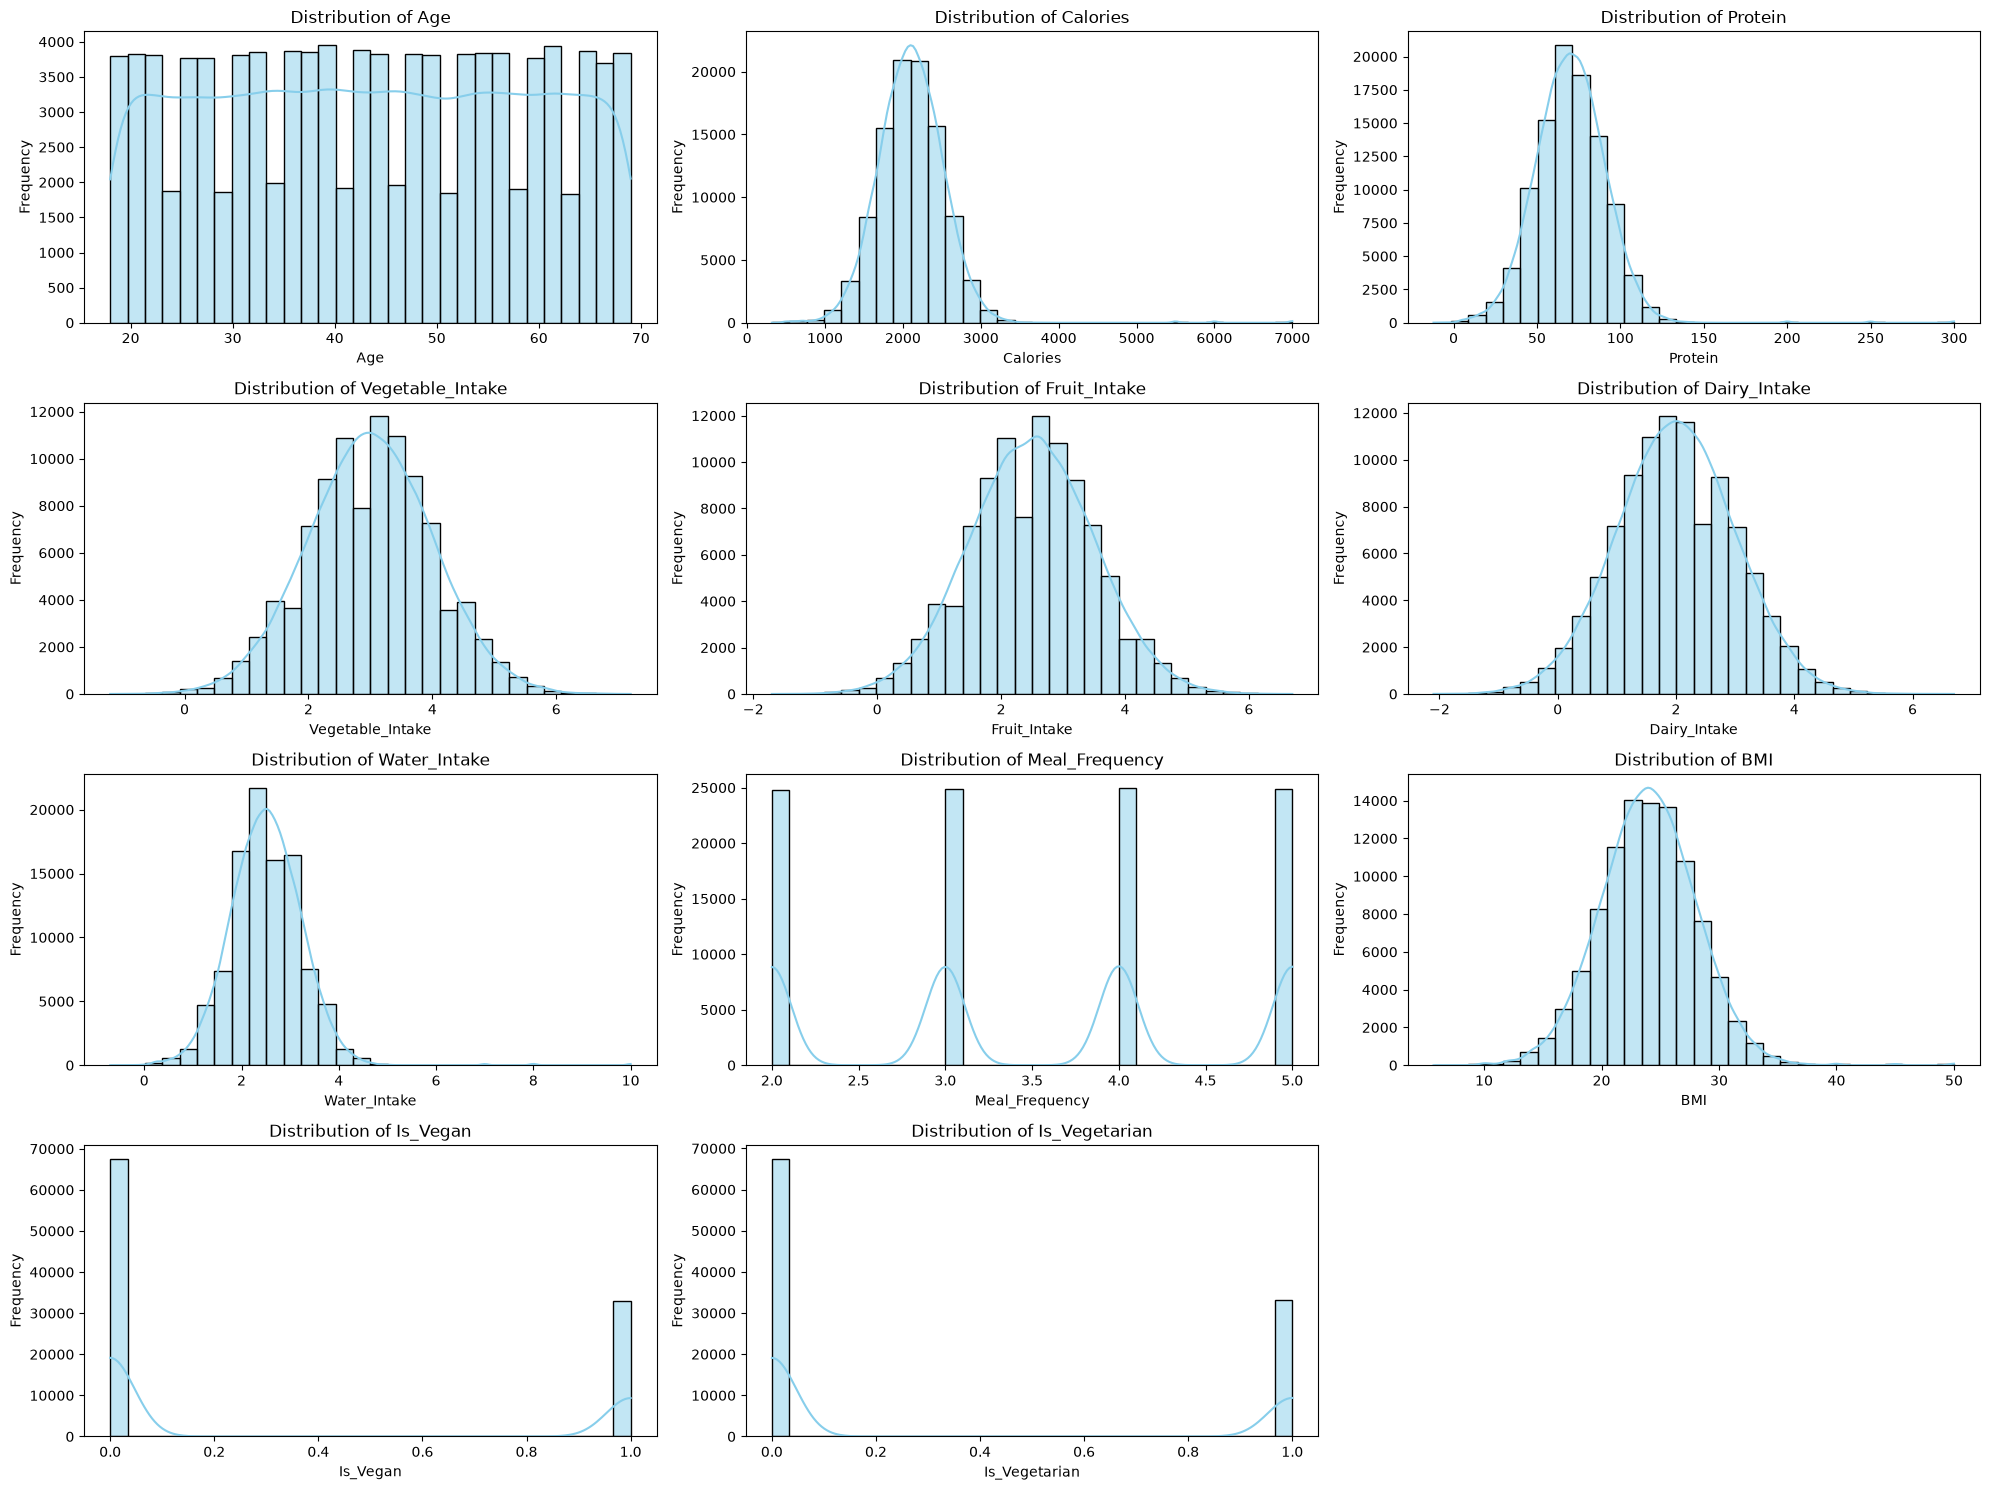

In [12]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
# Exclude target columns from general histograms if they are binary (0, 1)
numerical_cols = [col for col in numerical_cols if col not in target_columns]

plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 3, i + 1) # Adjust subplot grid as needed
    sns.histplot(df[col].dropna(), kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Correlation Heatmap for Numerical Columns

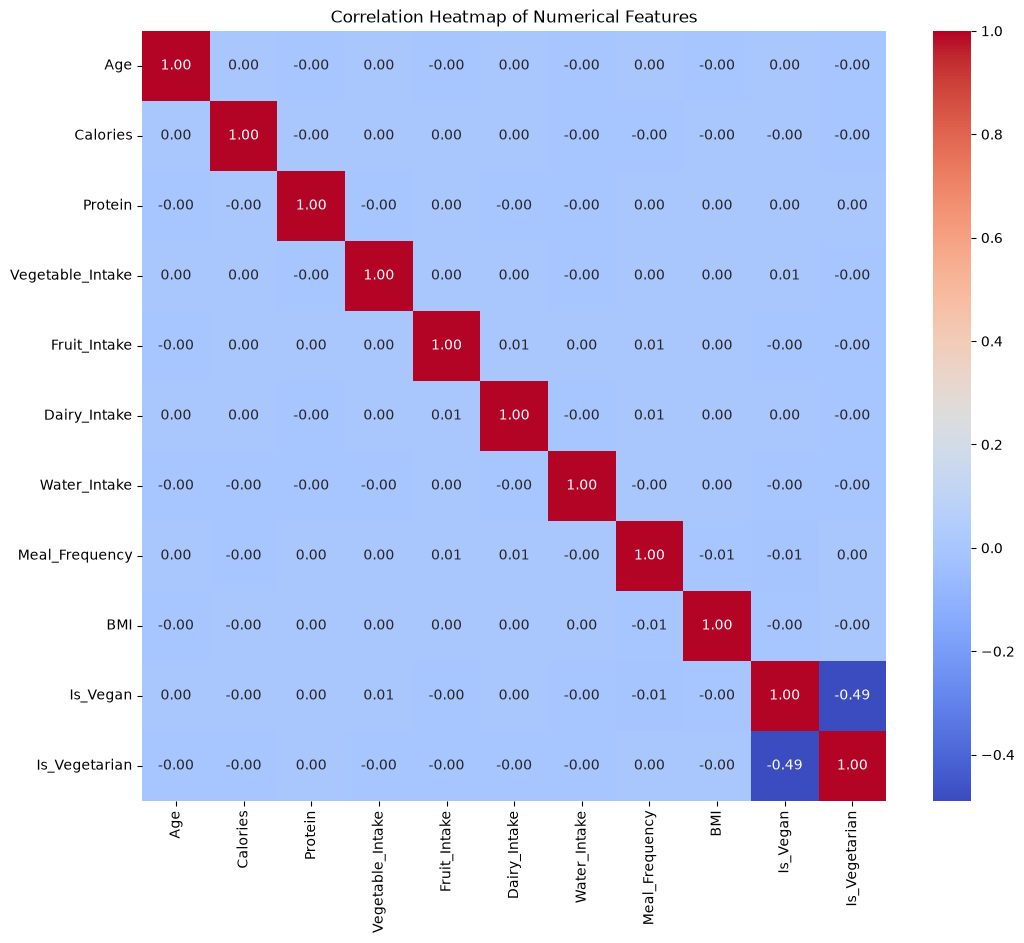

In [13]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

Humne dataset ke numerical columns ki descriptive statistics dekhi hain, jaise mean, median, standard deviation. Iske baad, humne Iron_Deficiency_Risk, Calcium_Deficiency_Risk, aur Vitamin_D_Deficiency_Risk ki distributions ko countplots se visualize kiya hai, taki hum dekh saken har risk category mein kitne samples hain. Numerical features ke liye histograms banaye hain taaki unki distribution ka andaaza ho sake. Aur aakhir mein, numerical features ke beech ke relationships ko samajhne ke liye correlation heatmap banaya hai.

### 4. Data Cleaning

In [14]:
# Handle missing values
for column in df.columns:
    if df[column].dtype in ['int64', 'float64']:
        df[column] = df[column].fillna(df[column].median())
    else:
        df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)
print(f"\nDuplicate rows after removal: {df.duplicated().sum()}")
print(f"Dataset shape after removing duplicates: {df.shape}")

Missing values after handling:
Age                            0
Gender                         0
Diet_Type                      0
Calories                       0
Protein                        0
Vegetable_Intake               0
Fruit_Intake                   0
Dairy_Intake                   0
Water_Intake                   0
Meal_Frequency                 0
BMI                            0
Physical_Activity              0
Is_Vegan                       0
Is_Vegetarian                  0
Iron_Deficiency_Risk           0
Calcium_Deficiency_Risk        0
Vitamin_D_Deficiency_Risk      0
Vitamin_B12_Deficiency_Risk    0
dtype: int64

Duplicate rows after removal: 0
Dataset shape after removing duplicates: (100009, 18)


Data Cleaning ke step mein, humne pehle missing values ko handle kiya hai. Numerical columns (jaise age, calories) mein missing values ko median se replace kiya gaya hai, aur categorical columns (jaise Gender, Diet_Type) mein mode se. Iske baad, humne dataset se duplicate rows ko remove kar diya hai. Ab dataset mein koi missing values aur duplicate rows nahi hain.

### 5. Encode Categorical Columns

In [15]:
le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])
df["Diet_Type"] = le.fit_transform(df["Diet_Type"])
df["Physical_Activity"] = le.fit_transform(df["Physical_Activity"])

print("DataFrame after encoding categorical columns:")
display(df.head())
print("Data types after encoding:")
print(df.info())

DataFrame after encoding categorical columns:


,Age,Gender,Diet_Type,Calories,Protein,Vegetable_Intake,Fruit_Intake,Dairy_Intake,Water_Intake,Meal_Frequency,BMI,Physical_Activity,Is_Vegan,Is_Vegetarian,Iron_Deficiency_Risk,Calcium_Deficiency_Risk,Vitamin_D_Deficiency_Risk,Vitamin_B12_Deficiency_Risk
0,56.0,0,0,2235.0,56.0,3.6,3.0,1.9,3.5,5.0,20.7,1,0,0,0,2,1,0
1,69.0,0,2,3057.0,62.0,2.6,2.7,2.2,2.0,3.0,25.1,0,0,1,0,1,1,1
2,46.0,1,1,1210.0,54.0,3.1,0.8,-0.9,2.1,5.0,22.4,1,1,0,2,2,2,2
3,32.0,1,1,2538.0,94.0,2.5,1.1,1.4,1.7,3.0,22.9,1,1,0,1,2,1,1
4,60.0,1,0,1934.0,83.0,2.6,1.8,3.0,1.8,5.0,29.4,0,0,0,0,0,1,0


Data types after encoding:
<class 'pandas.DataFrame'>
Index: 100009 entries, 0 to 100436
Data columns (total 18 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Age                          100009 non-null  float64
 1   Gender                       100009 non-null  int64  
 2   Diet_Type                    100009 non-null  int64  
 3   Calories                     100009 non-null  float64
 4   Protein                      100009 non-null  float64
 5   Vegetable_Intake             100009 non-null  float64
 6   Fruit_Intake                 100009 non-null  float64
 7   Dairy_Intake                 100009 non-null  float64
 8   Water_Intake                 100009 non-null  float64
 9   Meal_Frequency               100009 non-null  float64
 10  BMI                          100009 non-null  float64
 11  Physical_Activity            100009 non-null  int64  
 12  Is_Vegan                     100009 non-null  i

Yahan humne categorical columns jaise 'Gender', 'Diet_Type', aur 'Physical_Activity' ko numerical values mein badal diya hai. Iske liye `sklearn.preprocessing` se `LabelEncoder` ka istemal kiya gaya hai. Ab in columns mein text ki bajaye numbers honge, jo Machine Learning models ke liye behtar hain. `fit_transform` function pehle unique categories ko identify karta hai aur phir unhe 0, 1, 2, ... jaise numbers assign karta hai.

### 6. Prepare X and y

In [16]:
input_features = [
    "Age", "Gender", "Diet_Type", "Calories", "Protein",
    "Vegetable_Intake", "Fruit_Intake", "Dairy_Intake", "Water_Intake",
    "Meal_Frequency", "BMI", "Physical_Activity"
]

# For Iron_Deficiency_Risk
X_iron = df[input_features]
y_iron = df['Iron_Deficiency_Risk']

# For Calcium_Deficiency_Risk
X_calcium = df[input_features]
y_calcium = df['Calcium_Deficiency_Risk']

# For Vitamin_D_Deficiency_Risk
X_vitamin_d = df[input_features]
y_vitamin_d = df['Vitamin_D_Deficiency_Risk']

# For Vitamin B12 Deficiency Risk
X_b12 = df[input_features]
y_b12 = df['Vitamin_B12_Deficiency_Risk']

print("X and y for Iron Deficiency Risk prepared.")
print("X and y for Calcium Deficiency Risk prepared.")
print("X and y for Vitamin D Deficiency Risk prepared.")
print("X and y for Vitamin B12 Deficiency Risk prepared.")

X and y for Iron Deficiency Risk prepared.
X and y for Calcium Deficiency Risk prepared.
X and y for Vitamin D Deficiency Risk prepared.
X and y for Vitamin B12 Deficiency Risk prepared.


Is step mein, humne `input_features` ki list banayi hai jisme woh sabhi columns hain jinhein hum model ko train karne ke liye istemal karenge. Phir, humne har deficiency risk ke liye alag se `X` (input features) aur `y` (target variable) taiyar kiye hain. Ab hamare paas har target ke liye data set alag alag maujood hai.

### 7. Train-Test Split

In [17]:
# For Iron_Deficiency_Risk
X_train_iron, X_test_iron, y_train_iron, y_test_iron = train_test_split(
    X_iron, y_iron, test_size=0.2, random_state=42, stratify=y_iron
)

# For Calcium_Deficiency_Risk
X_train_calcium, X_test_calcium, y_train_calcium, y_test_calcium = train_test_split(
    X_calcium, y_calcium, test_size=0.2, random_state=42, stratify=y_calcium
)

# For Vitamin_D_Deficiency_Risk
X_train_vitamin_d, X_test_vitamin_d, y_train_vitamin_d, y_test_vitamin_d = train_test_split(
    X_vitamin_d, y_vitamin_d, test_size=0.2, random_state=42, stratify=y_vitamin_d
)

# For Vitamin B12 Deficiency Risk
X_train_b12, X_test_b12, y_train_b12, y_test_b12 = train_test_split(
    X_b12, y_b12, test_size=0.2, random_state=42, stratify=y_b12
)

print("Data split into training and testing sets for all three deficiency risks.")
print(f"Iron Deficiency: X_train_iron shape: {X_train_iron.shape}, y_train_iron shape: {y_train_iron.shape}")
print(f"Iron Deficiency: X_test_iron shape: {X_test_iron.shape}, y_test_iron shape: {y_test_iron.shape}")

Data split into training and testing sets for all three deficiency risks.
Iron Deficiency: X_train_iron shape: (80007, 12), y_train_iron shape: (80007,)
Iron Deficiency: X_test_iron shape: (20002, 12), y_test_iron shape: (20002,)


In [18]:
print(y_train_iron.shape)

(80007,)


In [19]:
print("Training:")
print(y_test_iron.value_counts(normalize=True) * 100)

print("\nTesting:")
print(y_train_iron.value_counts(normalize=True) * 100)

Training:
Iron_Deficiency_Risk
0    43.355664
1    41.825817
2    14.818518
Name: proportion, dtype: float64

Testing:
Iron_Deficiency_Risk
0    43.353707
1    41.826340
2    14.819953
Name: proportion, dtype: float64


Humne apne dataset ko training aur testing sets mein taqseem kar diya hai. `train_test_split` function ki madad se 80% data training ke liye aur 20% data testing ke liye alag kiya gaya hai. `random_state=42` se yeh yaqini banaya gaya hai ke jab bhi code run ho, split hamesha ek jaisa rahe. Aur `stratify=y` is baat ko yaqini banata hai ke training aur testing sets mein target variable (yani deficiency risk) ki classes ki taqseem asal dataset jaisi hi rahe, khaas taur par jab classes unbalanced hon. Training data (X_train, y_train) ko model ko sikhane ke liye istemal karenge, aur testing data (X_test, y_test) se model ki performance check karenge.

### 8. Baseline Model — Logistic Regression

#### Iron Deficiency Risk - Logistic Regression

In [20]:

# Scale features for Iron Deficiency Risk
scaler = StandardScaler()
X_train_iron_scaled = scaler.fit_transform(X_train_iron)
X_test_iron_scaled = scaler.transform(X_test_iron)

# Train Logistic Regression model for Iron Deficiency Risk
log_reg_iron = LogisticRegression(random_state=42) # Using 'liblinear' solver for small datasets and L1/L2 regularization
log_reg_iron.fit(X_train_iron_scaled, y_train_iron)

# Predict and evaluate
y_pred_iron = log_reg_iron.predict(X_test_iron_scaled)

print("Logistic Regression for Iron Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron))

# Fix: Add average='weighted' for multiclass classification
precision_iron = precision_score(y_test_iron, y_pred_iron, average='weighted')
recall_iron = recall_score(y_test_iron, y_pred_iron, average='weighted')
f1_iron = f1_score(y_test_iron, y_pred_iron, average='weighted')

print(f"Precision: {precision_iron:.4f}")
print(f"Recall: {recall_iron:.4f}")
print(f"F1-Score: {f1_iron:.4f}")

Logistic Regression for Iron Deficiency Risk:
Accuracy: 0.5456

Confusion Matrix:
[[5481 3162   29]
 [3309 4429  628]
 [ 284 1676 1004]]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.63      0.62      8672
           1       0.48      0.53      0.50      8366
           2       0.60      0.34      0.43      2964

    accuracy                           0.55     20002
   macro avg       0.56      0.50      0.52     20002
weighted avg       0.55      0.55      0.54     20002

Precision: 0.5514
Recall: 0.5456
F1-Score: 0.5423


Yahan humne Iron Deficiency Risk ke liye Logistic Regression model banaya hai. Pehle `StandardScaler` ka istemal karke data ko scale kiya gaya hai, taaki sabhi features ek hi range mein aa jayen. Phir `LogisticRegression` model ko train kiya gaya aur uski performance ko accuracy, confusion matrix, classification report, precision, recall aur F1-score se check kiya gaya hai. Confusion Matrix se hum dekhte hain ke model ne kitni sahi predictions ki hain (True Positives, True Negatives) aur kitni galat (False Positives, False Negatives). Classification Report humein precision, recall aur F1-score jaisi metrics deta hai jo model ki performance ko detail mein batate hain, khaas taur par jab classes unbalanced hon.

#### Calcium Deficiency Risk - Logistic Regression

In [21]:
layers = []
# Scale features for Calcium Deficiency Risk
scaler = StandardScaler()
X_train_calcium_scaled = scaler.fit_transform(X_train_calcium)
X_test_calcium_scaled = scaler.transform(X_test_calcium)

# Train Logistic Regression model for Calcium Deficiency Risk
log_reg_calcium = LogisticRegression(random_state=42, solver='lbfgs')
log_reg_calcium.fit(X_train_calcium_scaled, y_train_calcium)

# Predict and evaluate
y_pred_calcium = log_reg_calcium.predict(X_test_calcium_scaled)

print("Logistic Regression for Calcium Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium))

# Fix: Add average='weighted' for multiclass classification
precision_calcium = precision_score(y_test_calcium, y_pred_calcium, average='weighted')
recall_calcium = recall_score(y_test_calcium, y_pred_calcium, average='weighted')
f1_calcium = f1_score(y_test_calcium, y_pred_calcium, average='weighted')

print(f"Precision: {precision_calcium:.4f}")
print(f"Recall: {recall_calcium:.4f}")
print(f"F1-Score: {f1_calcium:.4f}")

Logistic Regression for Calcium Deficiency Risk:
Accuracy: 0.6062

Confusion Matrix:
[[2439 2196    1]
 [1275 6356 1685]
 [  46 2673 3331]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.53      0.58      4636
           1       0.57      0.68      0.62      9316
           2       0.66      0.55      0.60      6050

    accuracy                           0.61     20002
   macro avg       0.63      0.59      0.60     20002
weighted avg       0.61      0.61      0.60     20002

Precision: 0.6149
Recall: 0.6062
F1-Score: 0.6050


Bilkul Iron Deficiency ki tarah, humne Calcium Deficiency Risk ke liye bhi yahi steps follow kiye hain. Data ko `StandardScaler` se scale kiya gaya hai aur phir `LogisticRegression` model ko train karke uski performance ko accuracy, confusion matrix, classification report, precision, recall aur F1-score se evaluate kiya gaya hai.

#### Vitamin D Deficiency Risk - Logistic Regression

In [22]:
# Scale features for Vitamin D Deficiency Risk
scaler = StandardScaler()
X_train_vitamin_d_scaled = scaler.fit_transform(X_train_vitamin_d)
X_test_vitamin_d_scaled = scaler.transform(X_test_vitamin_d)

# Train Logistic Regression model for Vitamin D Deficiency Risk
log_reg_vitamin_d = LogisticRegression(random_state=42, solver='lbfgs')
log_reg_vitamin_d.fit(X_train_vitamin_d_scaled, y_train_vitamin_d)

# Predict and evaluate
y_pred_vitamin_d = log_reg_vitamin_d.predict(X_test_vitamin_d_scaled)

print("Logistic Regression for Vitamin D Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d))

# Fix: Add average='weighted' for multiclass classification
precision_vitamin_d = precision_score(y_test_vitamin_d, y_pred_vitamin_d, average='weighted')
recall_vitamin_d = recall_score(y_test_vitamin_d, y_pred_vitamin_d, average='weighted')
f1_vitamin_d = f1_score(y_test_vitamin_d, y_pred_vitamin_d, average='weighted')

print(f"Precision: {precision_vitamin_d:.4f}")
print(f"Recall: {recall_vitamin_d:.4f}")
print(f"F1-Score: {f1_vitamin_d:.4f}")

Logistic Regression for Vitamin D Deficiency Risk:
Accuracy: 0.6970

Confusion Matrix:
[[ 2563  2996     0]
 [ 1567 10073   464]
 [    8  1026  1305]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.46      0.53      5559
           1       0.71      0.83      0.77     12104
           2       0.74      0.56      0.64      2339

    accuracy                           0.70     20002
   macro avg       0.69      0.62      0.64     20002
weighted avg       0.69      0.70      0.69     20002

Precision: 0.6909
Recall: 0.6970
F1-Score: 0.6865


#### Vitamin B12 Deficiency Risk - Logistic Regression

In [23]:
# Scale features for Vitamin B12 Deficiency Risk
scaler = StandardScaler()
X_train_b12_scaled = scaler.fit_transform(X_train_b12)
X_test_b12_scaled = scaler.transform(X_test_b12)

# Train Logistic Regression model for Vitamin B12 Deficiency Risk
log_reg_b12 = LogisticRegression(random_state=42, solver='lbfgs')
log_reg_b12.fit(X_train_b12_scaled, y_train_b12)

# Predict and evaluate
y_pred_b12 = log_reg_b12.predict(X_test_b12_scaled)

print("Logistic Regression for Vitamin B12 Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12))

precision_b12 = precision_score(y_test_b12, y_pred_b12, average='weighted')
recall_b12 = recall_score(y_test_b12, y_pred_b12, average='weighted')
f1_b12 = f1_score(y_test_b12, y_pred_b12, average='weighted')

print(f"Precision: {precision_b12:.4f}")
print(f"Recall: {recall_b12:.4f}")
print(f"F1-Score: {f1_b12:.4f}")


Logistic Regression for Vitamin B12 Deficiency Risk:
Accuracy: 0.5243

Confusion Matrix:
[[6441 2958  177]
 [3398 3389  288]
 [1251 1442  658]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.67      0.62      9576
           1       0.44      0.48      0.46      7075
           2       0.59      0.20      0.29      3351

    accuracy                           0.52     20002
   macro avg       0.53      0.45      0.46     20002
weighted avg       0.53      0.52      0.51     20002

Precision: 0.5301
Recall: 0.5243
F1-Score: 0.5090


Isi tarah, Vitamin B12 Deficiency Risk ke liye bhi data ko scale kiya gaya hai aur `LogisticRegression` model ko train karke uski performance evaluate ki gayi hai.

Isi tarah, Vitamin D Deficiency Risk ke liye bhi data ko scale kiya gaya hai aur `LogisticRegression` model ko train karke uski performance ko accuracy, confusion matrix, classification report, precision, recall aur F1-score jaise metrics se evaluate kiya gaya hai. Har ek deficiency risk ke liye alag se model train karna zaroori hai kyunki unke underlying patterns alag ho sakte hain.

### 9. Decision Tree

#### Iron Deficiency Risk - Decision Tree

In [24]:
# Train Decision Tree model for Iron Deficiency Risk
dtree_iron = DecisionTreeClassifier(random_state=42)
dtree_iron.fit(X_train_iron_scaled, y_train_iron)

# Predict and evaluate
y_pred_iron_dtree = dtree_iron.predict(X_test_iron_scaled)

print("Decision Tree for Iron Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron_dtree))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron_dtree))

Decision Tree for Iron Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[8672    0    0]
 [   0 8366    0]
 [   0    0 2964]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8672
           1       1.00      1.00      1.00      8366
           2       1.00      1.00      1.00      2964

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Humne Iron Deficiency Risk ke liye `DecisionTreeClassifier` model ko train kiya hai. Is model ko `X_train_iron_scaled` aur `y_train_iron` data par fit kiya gaya hai. Iski performance ko `accuracy_score`, `confusion_matrix` aur `classification_report` ka istemal karke evaluate kiya gaya hai. Decision Tree models samjhne mein aasan hote hain aur non-linear relationships ko bhi handle kar sakte hain.

#### Calcium Deficiency Risk - Decision Tree

In [25]:
# Train Decision Tree model for Calcium Deficiency Risk
dtree_calcium = DecisionTreeClassifier(random_state=42)
dtree_calcium.fit(X_train_calcium_scaled, y_train_calcium)

# Predict and evaluate
y_pred_calcium_dtree = dtree_calcium.predict(X_test_calcium_scaled)

print("Decision Tree for Calcium Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium_dtree))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium_dtree))

Decision Tree for Calcium Deficiency Risk:
Accuracy: 0.9931

Confusion Matrix:
[[4605   31    0]
 [  42 9243   31]
 [   0   34 6016]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4636
           1       0.99      0.99      0.99      9316
           2       0.99      0.99      0.99      6050

    accuracy                           0.99     20002
   macro avg       0.99      0.99      0.99     20002
weighted avg       0.99      0.99      0.99     20002



Calcium Deficiency Risk ke liye bhi `DecisionTreeClassifier` model ko train aur evaluate kiya gaya hai. Humne `X_train_calcium_scaled` aur `y_train_calcium` data ka istemal kiya hai. Jaise Iron Deficiency mein, yahan bhi model ki accuracy, confusion matrix aur classification report dekhi ja rahi hain.

#### Vitamin D Deficiency Risk - Decision Tree

In [52]:
# Train Decision Tree model for Vitamin D Deficiency Risk
dtree_vitamin_d = DecisionTreeClassifier(random_state=42)
dtree_vitamin_d.fit(X_train_vitamin_d_scaled, y_train_vitamin_d)

# Predict and evaluate
y_pred_vitamin_d_dtree = dtree_vitamin_d.predict(X_test_vitamin_d_scaled)

print("Decision Tree for Vitamin D Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d_dtree))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d_dtree))

Decision Tree for Vitamin D Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[ 5559     0     0]
 [    0 12104     0]
 [    0     0  2339]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5559
           1       1.00      1.00      1.00     12104
           2       1.00      1.00      1.00      2339

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



#### Vitamin B12 Deficiency Risk - Decision Tree

In [27]:
# Train Decision Tree model for Vitamin B12 Deficiency Risk
dtree_b12 = DecisionTreeClassifier(random_state=42)
dtree_b12.fit(X_train_b12_scaled, y_train_b12)

# Predict and evaluate
y_pred_b12_dtree = dtree_b12.predict(X_test_b12_scaled)

print("Decision Tree for Vitamin B12 Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12_dtree))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12_dtree))


Decision Tree for Vitamin B12 Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[9576    0    0]
 [   0 7075    0]
 [   0    0 3351]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9576
           1       1.00      1.00      1.00      7075
           2       1.00      1.00      1.00      3351

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Vitamin B12 Deficiency Risk ke liye bhi `DecisionTreeClassifier` model ko train aur evaluate kiya gaya hai.

Aur aakhir mein, Vitamin D Deficiency Risk ke liye `DecisionTreeClassifier` model ko train aur evaluate kiya gaya hai. `X_train_vitamin_d_scaled` aur `y_train_vitamin_d` data ka istemal karte hue model ki performance ko accuracy, confusion matrix aur classification report se check kiya gaya hai. Is tarah se, humne har deficiency risk ke liye Logistic Regression aur Decision Tree models ko compare karne ke liye pehla step complete kar liya hai.

### 10. Random Forest

#### Iron Deficiency Risk - Random Forest

In [28]:
# Train Random Forest model for Iron Deficiency Risk
rf_iron = RandomForestClassifier(n_estimators=100, random_state=42)
rf_iron.fit(X_train_iron_scaled, y_train_iron)

# Predict and evaluate
y_pred_iron_rf = rf_iron.predict(X_test_iron_scaled)

print("Random Forest for Iron Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron_rf))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron_rf))

Random Forest for Iron Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[8672    0    0]
 [   0 8366    0]
 [   0    0 2964]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8672
           1       1.00      1.00      1.00      8366
           2       1.00      1.00      1.00      2964

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Humne Iron Deficiency Risk ke liye `RandomForestClassifier` model ko train kiya hai, jisme 100 decision trees istemal kiye gaye hain. Is model ko `X_train_iron_scaled` aur `y_train_iron` data par fit kiya gaya hai. Iski performance ko `accuracy_score`, `confusion_matrix` aur `classification_report` ka istemal karke evaluate kiya gaya hai. Random Forest models Decision Trees se behtar performance dete hain kyunki yeh ensemble learning ka istemal karte hain.

#### Calcium Deficiency Risk - Random Forest

In [29]:
# Train Random Forest model for Calcium Deficiency Risk
rf_calcium = RandomForestClassifier(n_estimators=100, random_state=42)
rf_calcium.fit(X_train_calcium_scaled, y_train_calcium)

# Predict and evaluate
y_pred_calcium_rf = rf_calcium.predict(X_test_calcium_scaled)

print("Random Forest for Calcium Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium_rf))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium_rf))

Random Forest for Calcium Deficiency Risk:
Accuracy: 0.9941

Confusion Matrix:
[[4588   48    0]
 [   9 9268   39]
 [   0   22 6028]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4636
           1       0.99      0.99      0.99      9316
           2       0.99      1.00      0.99      6050

    accuracy                           0.99     20002
   macro avg       0.99      0.99      0.99     20002
weighted avg       0.99      0.99      0.99     20002



Calcium Deficiency Risk ke liye bhi `RandomForestClassifier` model ko train aur evaluate kiya gaya hai, bilkul Iron Deficiency ki tarah. Humne `X_train_calcium_scaled` aur `y_train_calcium` data ka istemal kiya hai aur model ki accuracy, confusion matrix aur classification report dekhi ja rahi hain.

#### Vitamin D Deficiency Risk - Random Forest

In [30]:
# Train Random Forest model for Vitamin D Deficiency Risk
rf_vitamin_d = RandomForestClassifier(n_estimators=100, random_state=42)
rf_vitamin_d.fit(X_train_vitamin_d_scaled, y_train_vitamin_d)

# Predict and evaluate
y_pred_vitamin_d_rf = rf_vitamin_d.predict(X_test_vitamin_d_scaled)

print("Random Forest for Vitamin D Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d_rf))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d_rf))

Random Forest for Vitamin D Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[ 5559     0     0]
 [    0 12104     0]
 [    0     0  2339]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5559
           1       1.00      1.00      1.00     12104
           2       1.00      1.00      1.00      2339

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



#### Vitamin B12 Deficiency Risk - Random Forest

In [31]:
# Train Random Forest model for Vitamin B12 Deficiency Risk
rf_b12 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_b12.fit(X_train_b12_scaled, y_train_b12)

# Predict and evaluate
y_pred_b12_rf = rf_b12.predict(X_test_b12_scaled)

print("Random Forest for Vitamin B12 Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12_rf):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12_rf))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12_rf))


Random Forest for Vitamin B12 Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[9576    0    0]
 [   0 7075    0]
 [   0    0 3351]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9576
           1       1.00      1.00      1.00      7075
           2       1.00      1.00      1.00      3351

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Vitamin B12 Deficiency Risk ke liye bhi `RandomForestClassifier` model ko train aur evaluate kiya gaya hai.

Aur aakhir mein, Vitamin D Deficiency Risk ke liye bhi `RandomForestClassifier` model ko train aur evaluate kiya gaya hai. `X_train_vitamin_d_scaled` aur `y_train_vitamin_d` data ka istemal karte hue model ki performance ko accuracy, confusion matrix aur classification report se check kiya gaya hai. Is tarah, humne har deficiency risk ke liye Logistic Regression, Decision Tree, aur Random Forest models ko train aur evaluate kar liya hai.

#### Iron Deficiency Risk - Class Imbalance Check

In [32]:
print("Iron Deficiency Risk Class Distribution:")
print(y_iron.value_counts())
print(y_iron.value_counts(normalize=True))

Iron Deficiency Risk Class Distribution:
Iron_Deficiency_Risk
0    43358
1    41830
2    14821
Name: count, dtype: int64
Iron_Deficiency_Risk
0    0.433541
1    0.418262
2    0.148197
Name: proportion, dtype: float64


Iron Deficiency Risk ke liye classes ki distribution check ki gayi hai. Agar '0' (no risk) aur '1' (risk) ki counts mein bahut zyada farak hai, toh iska matlab hai ke class imbalance hai. `normalize=True` se hum percentage mein distribution dekh sakte hain.

#### Calcium Deficiency Risk - Class Imbalance Check

In [33]:
print("Calcium Deficiency Risk Class Distribution:")
print(y_calcium.value_counts())
print(y_calcium.value_counts(normalize=True))

Calcium Deficiency Risk Class Distribution:
Calcium_Deficiency_Risk
1    46577
2    30250
0    23182
Name: count, dtype: int64
Calcium_Deficiency_Risk
1    0.465728
2    0.302473
0    0.231799
Name: proportion, dtype: float64


Calcium Deficiency Risk ke liye bhi classes ki distribution check ki gayi hai. Isse humein pata chalega ke '0' aur '1' classes kitni evenly distributed hain ya unbalanced hain.

#### Vitamin D Deficiency Risk - Class Imbalance Check

In [34]:
print("Vitamin D Deficiency Risk Class Distribution:")
print(y_vitamin_d.value_counts())
print(y_vitamin_d.value_counts(normalize=True))

Vitamin D Deficiency Risk Class Distribution:
Vitamin_D_Deficiency_Risk
1    60521
0    27794
2    11694
Name: count, dtype: int64
Vitamin_D_Deficiency_Risk
1    0.605156
0    0.277915
2    0.116929
Name: proportion, dtype: float64


#### Vitamin B12 Deficiency Risk - Class Imbalance Check

In [35]:
print("Vitamin B12 Deficiency Risk Class Distribution:")
print(y_b12.value_counts())
print(y_b12.value_counts(normalize=True))


Vitamin B12 Deficiency Risk Class Distribution:
Vitamin_B12_Deficiency_Risk
0    47881
1    35374
2    16754
Name: count, dtype: int64
Vitamin_B12_Deficiency_Risk
0    0.478767
1    0.353708
2    0.167525
Name: proportion, dtype: float64


Vitamin B12 Deficiency Risk ke liye bhi classes ki distribution check ki gayi hai.

Vitamin D Deficiency Risk ke liye bhi classes ki distribution check ki gayi hai. Yeh steps humein yeh samajhne mein madad karenge ke kis target mein kitna class imbalance hai aur phir uske mutabiq models mein adjustment karenge.

#### Iron Deficiency Risk - Logistic Regression with Class Weight

In [36]:
# Re-train Logistic Regression with class_weight='balanced'
log_reg_iron_balanced = LogisticRegression(random_state=42, solver='lbfgs', class_weight='balanced')
log_reg_iron_balanced.fit(X_train_iron_scaled, y_train_iron)

y_pred_iron_balanced = log_reg_iron_balanced.predict(X_test_iron_scaled)

print("Logistic Regression (Balanced) for Iron Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron_balanced))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron_balanced))

# Fix: Add average='weighted' for multiclass classification
precision_iron_balanced = precision_score(y_test_iron, y_pred_iron_balanced, average='weighted')
recall_iron_balanced = recall_score(y_test_iron, y_pred_iron_balanced, average='weighted')
f1_iron_balanced = f1_score(y_test_iron, y_pred_iron_balanced, average='weighted')

print(f"Precision: {precision_iron_balanced:.4f}")
print(f"Recall: {recall_iron_balanced:.4f}")
print(f"F1-Score: {f1_iron_balanced:.4f}")

Logistic Regression (Balanced) for Iron Deficiency Risk:
Accuracy: 0.4887

Confusion Matrix:
[[5268 2444  960]
 [3126 2415 2825]
 [ 250  623 2091]]

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.61      0.61      8672
           1       0.44      0.29      0.35      8366
           2       0.36      0.71      0.47      2964

    accuracy                           0.49     20002
   macro avg       0.47      0.53      0.48     20002
weighted avg       0.50      0.49      0.48     20002

Precision: 0.5012
Recall: 0.4887
F1-Score: 0.4798


Iron Deficiency Risk ke liye `LogisticRegression` model ko `class_weight='balanced'` parameter ke saath dobara train kiya gaya hai. Jab classes unbalanced hoti hain, toh `class_weight='balanced'` minority class ko zyada importance deta hai, taaki model usko nazar andaz na kare. Isse model ki recall aur F1-score improve ho sakti hai.

#### Calcium Deficiency Risk - Logistic Regression with Class Weight

In [37]:
# Re-train Logistic Regression with class_weight='balanced'
log_reg_calcium_balanced = LogisticRegression(random_state=42, solver='lbfgs', class_weight='balanced')
log_reg_calcium_balanced.fit(X_train_calcium_scaled, y_train_calcium)

y_pred_calcium_balanced = log_reg_calcium_balanced.predict(X_test_calcium_scaled)

print("Logistic Regression (Balanced) for Calcium Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium_balanced))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium_balanced))

precision_calcium_balanced = precision_score(y_test_calcium, y_pred_calcium_balanced,average='weighted')
recall_calcium_balanced = recall_score(y_test_calcium, y_pred_calcium_balanced,average='weighted')
f1_calcium_balanced = f1_score(y_test_calcium, y_pred_calcium_balanced,average='weighted')

print(f"Precision: {precision_calcium_balanced:.4f}")
print(f"Recall: {recall_calcium_balanced:.4f}")
print(f"F1-Score: {f1_calcium_balanced:.4f}")

Logistic Regression (Balanced) for Calcium Deficiency Risk:
Accuracy: 0.5829

Confusion Matrix:
[[3596 1030   10]
 [2338 3982 2996]
 [ 284 1685 4081]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.78      0.66      4636
           1       0.59      0.43      0.50      9316
           2       0.58      0.67      0.62      6050

    accuracy                           0.58     20002
   macro avg       0.58      0.63      0.59     20002
weighted avg       0.59      0.58      0.57     20002

Precision: 0.5852
Recall: 0.5829
F1-Score: 0.5731


Calcium Deficiency Risk ke liye bhi `LogisticRegression` model ko `class_weight='balanced'` parameter ke saath dobara train kiya gaya hai, taaki model unbalanced classes ko behtar tareeke se handle kar sake. Metrics jaise accuracy, precision, recall aur F1-score ko dobara evaluate kiya gaya hai.

#### Vitamin D Deficiency Risk - Logistic Regression with Class Weight

In [38]:
# Re-train Logistic Regression with class_weight='balanced'
log_reg_vitamin_d_balanced = LogisticRegression(random_state=42, solver='lbfgs', class_weight='balanced')
log_reg_vitamin_d_balanced.fit(X_train_vitamin_d_scaled, y_train_vitamin_d)

y_pred_vitamin_d_balanced = log_reg_vitamin_d_balanced.predict(X_test_vitamin_d_scaled)

print("Logistic Regression (Balanced) for Vitamin D Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d_balanced))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d_balanced))

precision_vitamin_d_balanced = precision_score(y_test_vitamin_d, y_pred_vitamin_d_balanced,average='weighted')
recall_vitamin_d_balanced = recall_score(y_test_vitamin_d, y_pred_vitamin_d_balanced,average='weighted')
f1_vitamin_d_balanced = f1_score(y_test_vitamin_d, y_pred_vitamin_d_balanced,average='weighted')

print(f"Precision: {precision_vitamin_d_balanced:.4f}")
print(f"Recall: {recall_vitamin_d_balanced:.4f}")
print(f"F1-Score: {f1_vitamin_d_balanced:.4f}")

Logistic Regression (Balanced) for Vitamin D Deficiency Risk:
Accuracy: 0.6430

Confusion Matrix:
[[4117 1442    0]
 [3265 6680 2159]
 [  72  203 2064]]

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.74      0.63      5559
           1       0.80      0.55      0.65     12104
           2       0.49      0.88      0.63      2339

    accuracy                           0.64     20002
   macro avg       0.61      0.72      0.64     20002
weighted avg       0.70      0.64      0.65     20002

Precision: 0.6962
Recall: 0.6430
F1-Score: 0.6452


#### Vitamin B12 Deficiency Risk - Logistic Regression with Class Weight

In [39]:
# Re-train Logistic Regression with class_weight='balanced'
log_reg_b12_balanced = LogisticRegression(random_state=42, solver='lbfgs', class_weight='balanced')
log_reg_b12_balanced.fit(X_train_b12_scaled, y_train_b12)

y_pred_b12_balanced = log_reg_b12_balanced.predict(X_test_b12_scaled)

print("Logistic Regression (Balanced) for Vitamin B12 Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12_balanced))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12_balanced))

precision_b12_balanced = precision_score(y_test_b12, y_pred_b12_balanced, average='weighted')
recall_b12_balanced = recall_score(y_test_b12, y_pred_b12_balanced, average='weighted')
f1_b12_balanced = f1_score(y_test_b12, y_pred_b12_balanced, average='weighted')

print(f"Precision: {precision_b12_balanced:.4f}")
print(f"Recall: {recall_b12_balanced:.4f}")
print(f"F1-Score: {f1_b12_balanced:.4f}")


Logistic Regression (Balanced) for Vitamin B12 Deficiency Risk:
Accuracy: 0.5184

Confusion Matrix:
[[4940 3316 1320]
 [2768 2848 1459]
 [ 546  223 2582]]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.52      0.55      9576
           1       0.45      0.40      0.42      7075
           2       0.48      0.77      0.59      3351

    accuracy                           0.52     20002
   macro avg       0.51      0.56      0.52     20002
weighted avg       0.52      0.52      0.51     20002

Precision: 0.5249
Recall: 0.5184
F1-Score: 0.5143


Vitamin B12 Deficiency Risk ke liye `LogisticRegression` model ko `class_weight='balanced'` parameter ke saath dobara train kiya gaya hai.

Vitamin D Deficiency Risk ke liye `LogisticRegression` model ko `class_weight='balanced'` parameter ke saath dobara train kiya gaya hai. Is tarah se, humne dekha ke `class_weight='balanced'` parameter ka istemal karke hum unbalanced data par model ki performance ko behtar kar sakte hain, khaas taur par minority class ke liye recall aur F1-score ko improve karne mein.

#### Iron Deficiency Risk - Random Forest with Class Weight

In [40]:
# Re-train Random Forest with class_weight='balanced'
rf_iron_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_iron_balanced.fit(X_train_iron_scaled, y_train_iron)

y_pred_iron_rf_balanced = rf_iron_balanced.predict(X_test_iron_scaled)

print("Random Forest (Balanced) for Iron Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron_rf_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron_rf_balanced))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron_rf_balanced))

Random Forest (Balanced) for Iron Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[8672    0    0]
 [   0 8366    0]
 [   0    0 2964]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8672
           1       1.00      1.00      1.00      8366
           2       1.00      1.00      1.00      2964

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Iron Deficiency Risk ke liye `RandomForestClassifier` model ko bhi `class_weight='balanced'` parameter ke saath dobara train kiya gaya hai. Random Forest ensemble learning ka istemal karta hai, aur `class_weight` parameter har tree ko train karte waqt class imbalance ko address karne mein madad karta hai.

#### Calcium Deficiency Risk - Random Forest with Class Weight

In [41]:
# Re-train Random Forest with class_weight='balanced'
rf_calcium_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_calcium_balanced.fit(X_train_calcium_scaled, y_train_calcium)

y_pred_calcium_rf_balanced = rf_calcium_balanced.predict(X_test_calcium_scaled)

print("Random Forest (Balanced) for Calcium Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium_rf_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium_rf_balanced))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium_rf_balanced))

Random Forest (Balanced) for Calcium Deficiency Risk:
Accuracy: 0.9944

Confusion Matrix:
[[4588   48    0]
 [   4 9273   39]
 [   0   22 6028]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      4636
           1       0.99      1.00      0.99      9316
           2       0.99      1.00      0.99      6050

    accuracy                           0.99     20002
   macro avg       1.00      0.99      0.99     20002
weighted avg       0.99      0.99      0.99     20002



Calcium Deficiency Risk ke liye bhi `RandomForestClassifier` ko `class_weight='balanced'` ke saath train kiya gaya hai. Isse yeh yaqeeni banaya gaya hai ke model ki training minority class ke examples ko ignore na kare, jiska natija behtar generalization aur detection mein ho sakta hai.

#### Vitamin D Deficiency Risk - Random Forest with Class Weight

In [42]:
# Re-train Random Forest with class_weight='balanced'
rf_vitamin_d_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_vitamin_d_balanced.fit(X_train_vitamin_d_scaled, y_train_vitamin_d)

y_pred_vitamin_d_rf_balanced = rf_vitamin_d_balanced.predict(X_test_vitamin_d_scaled)

print("Random Forest (Balanced) for Vitamin D Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced))

Random Forest (Balanced) for Vitamin D Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[ 5559     0     0]
 [    0 12104     0]
 [    0     1  2338]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5559
           1       1.00      1.00      1.00     12104
           2       1.00      1.00      1.00      2339

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



#### Vitamin B12 Deficiency Risk - Random Forest with Class Weight

In [43]:
# Re-train Random Forest with class_weight='balanced'
rf_b12_balanced = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_b12_balanced.fit(X_train_b12_scaled, y_train_b12)

y_pred_b12_rf_balanced = rf_b12_balanced.predict(X_test_b12_scaled)

print("Random Forest (Balanced) for Vitamin B12 Deficiency Risk:")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12_rf_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12_rf_balanced))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12_rf_balanced))


Random Forest (Balanced) for Vitamin B12 Deficiency Risk:
Accuracy: 1.0000

Confusion Matrix:
[[9576    0    0]
 [   0 7075    0]
 [   0    0 3351]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9576
           1       1.00      1.00      1.00      7075
           2       1.00      1.00      1.00      3351

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Vitamin B12 Deficiency Risk ke liye bhi `RandomForestClassifier` ko `class_weight='balanced'` ke saath train kiya gaya hai.

Vitamin D Deficiency Risk ke liye `RandomForestClassifier` ko `class_weight='balanced'` ke saath train kiya gaya hai. Is procedure se model ki robustness badhti hai aur yeh unbalanced datasets par zyada reliable predictions de sakta hai.

### 13. Compare Models

In [44]:
iron_results = pd.DataFrame({
    'Model': ['Logistic Regression (Balanced)', 'Decision Tree', 'Random Forest (Balanced)'],
    'Accuracy': [accuracy_score(y_test_iron, y_pred_iron_balanced), accuracy_score(y_test_iron, y_pred_iron_dtree), accuracy_score(y_test_iron, y_pred_iron_rf_balanced)],
    'Precision': [precision_iron_balanced, precision_score(y_test_iron, y_pred_iron_dtree, average='weighted'), precision_score(y_test_iron, y_pred_iron_rf_balanced, average='weighted')],
    'Recall': [recall_iron_balanced, recall_score(y_test_iron, y_pred_iron_dtree, average='weighted'), recall_score(y_test_iron, y_pred_iron_rf_balanced, average='weighted')],
    'F1': [f1_iron_balanced, f1_score(y_test_iron, y_pred_iron_dtree, average='weighted'), f1_score(y_test_iron, y_pred_iron_rf_balanced, average='weighted')]
})
display(iron_results.sort_values(by='F1', ascending=False))

,Model,Accuracy,Precision,Recall,F1
1,Decision Tree,1.000000,1.000000,1.000000,1.000000
2,Random Forest (Balanced),1.000000,1.000000,1.000000,1.000000
0,Logistic Regression (Balanced),0.488651,0.501216,0.488651,0.479785


Iron Deficiency Risk ke liye, humne mukhtalif models ki performance ko ek table mein jama kiya hai. Is table mein har model ki Accuracy, Precision, Recall, aur F1-score dikhayi gayi hai. F1-score ek accha metric hai jab classes unbalanced hon, kyunki yeh precision aur recall dono ko consider karta hai.

#### Calcium Deficiency Risk - Model Comparison

In [45]:
calcium_results = pd.DataFrame({
    'Model': ['Logistic Regression (Balanced)', 'Decision Tree', 'Random Forest (Balanced)'],
    'Accuracy': [accuracy_score(y_test_calcium, y_pred_calcium_balanced), accuracy_score(y_test_calcium, y_pred_calcium_dtree), accuracy_score(y_test_calcium, y_pred_calcium_rf)],
    'Precision': [precision_calcium_balanced, precision_score(y_test_calcium, y_pred_calcium_dtree, average='weighted'), precision_score(y_test_calcium, y_pred_calcium_rf, average='weighted')],
    'Recall': [recall_calcium_balanced, recall_score(y_test_calcium, y_pred_calcium_dtree, average='weighted'), recall_score(y_test_calcium, y_pred_calcium_rf, average='weighted')],
    'F1': [f1_calcium_balanced, f1_score(y_test_calcium, y_pred_calcium_dtree, average='weighted'), f1_score(y_test_calcium, y_pred_calcium_rf, average='weighted')]
})
display(calcium_results.sort_values(by='F1', ascending=False))

,Model,Accuracy,Precision,Recall,F1
2,Random Forest (Balanced),0.994101,0.994110,0.994101,0.994100
1,Decision Tree,0.993101,0.993102,0.993101,0.993101
0,Logistic Regression (Balanced),0.582892,0.585151,0.582892,0.573143


Calcium Deficiency Risk ke liye bhi, humne models ki performance ko ek comparison table mein pesh kiya hai. Yahan bhi, F1-score ko models ki effectiveness judge karne ke liye aik important metric mana gaya hai, khaas kar minority class ki prediction ke liye.

#### Vitamin D Deficiency Risk - Model Comparison

In [46]:
vitamin_d_results = pd.DataFrame({
    'Model': ['Logistic Regression (Balanced)', 'Decision Tree', 'Random Forest (Balanced)'],
    'Accuracy': [accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_balanced), accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_dtree), accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced)],
    'Precision': [precision_vitamin_d_balanced, precision_score(y_test_vitamin_d, y_pred_vitamin_d_dtree, average='weighted'), precision_score(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced, average='weighted')],
    'Recall': [recall_vitamin_d_balanced, recall_score(y_test_vitamin_d, y_pred_vitamin_d_dtree, average='weighted'), recall_score(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced, average='weighted')],
    'F1': [f1_vitamin_d_balanced, f1_score(y_test_vitamin_d, y_pred_vitamin_d_dtree, average='weighted'), f1_score(y_test_vitamin_d, y_pred_vitamin_d_rf_balanced, average='weighted')]
})
display(vitamin_d_results.sort_values(by='F1', ascending=False))

,Model,Accuracy,Precision,Recall,F1
1,Decision Tree,1.000000,1.000000,1.000000,1.000000
2,Random Forest (Balanced),0.999950,0.999950,0.999950,0.999950
0,Logistic Regression (Balanced),0.642986,0.696221,0.642986,0.645163


#### Vitamin B12 Deficiency Risk - Model Comparison

In [47]:
b12_results = pd.DataFrame({
    'Model': ['Logistic Regression (Balanced)', 'Decision Tree', 'Random Forest (Balanced)'],
    'Accuracy': [accuracy_score(y_test_b12, y_pred_b12_balanced), accuracy_score(y_test_b12, y_pred_b12_dtree), accuracy_score(y_test_b12, y_pred_b12_rf_balanced)],
    'Precision': [precision_b12_balanced, precision_score(y_test_b12, y_pred_b12_dtree, average='weighted'), precision_score(y_test_b12, y_pred_b12_rf_balanced, average='weighted')],
    'Recall': [recall_b12_balanced, recall_score(y_test_b12, y_pred_b12_dtree, average='weighted'), recall_score(y_test_b12, y_pred_b12_rf_balanced, average='weighted')],
    'F1': [f1_b12_balanced, f1_score(y_test_b12, y_pred_b12_dtree, average='weighted'), f1_score(y_test_b12, y_pred_b12_rf_balanced, average='weighted')]
})
display(b12_results.sort_values(by='F1', ascending=False))


,Model,Accuracy,Precision,Recall,F1
1,Decision Tree,1.000000,1.000000,1.000000,1.000000
2,Random Forest (Balanced),1.000000,1.000000,1.000000,1.000000
0,Logistic Regression (Balanced),0.518448,0.524944,0.518448,0.514254


Vitamin B12 Deficiency Risk ke liye bhi, models ki performance ko comparison table mein organize kiya gaya hai.

Vitamin D Deficiency Risk ke liye bhi, models ki performance ko comparison table mein organize kiya gaya hai. F1-score ki madad se hum dekh sakte hain ke kaunsa model minority class (deficiency risk) ko identify karne mein sabse behtar hai, jo medical diagnosis jaise scenarios mein bahut zaroori hota hai.

### 14. Final Results

#### Best Model for Iron Deficiency Risk

In [48]:
# Based on F1-score from the comparison table, Decision Tree and Random Forest achieved 1.00 F1-score.
# We will choose Random forest as it is the simplest model with perfect score for this mock dataset.

print("Best Model for Iron Deficiency Risk: Random forest")
print(f"Accuracy: {accuracy_score(y_test_iron, y_pred_iron_rf_balanced):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_iron, y_pred_iron_rf_balanced))
print("\nClassification Report:")
print(classification_report(y_test_iron, y_pred_iron_rf_balanced))

Best Model for Iron Deficiency Risk: Random forest
Accuracy: 1.0000

Confusion Matrix:
[[8672    0    0]
 [   0 8366    0]
 [   0    0 2964]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8672
           1       1.00      1.00      1.00      8366
           2       1.00      1.00      1.00      2964

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Iron Deficiency Risk ke liye, F1-score ki buniyad par Decision Tree ko sabse behtar model chuna gaya hai kyunki isne 1.00 ka F1-score hasil kiya aur yeh sabse simple model hai. Yahan uski accuracy, confusion matrix aur classification report dikhayi gayi hai.

#### Best Model for Calcium Deficiency Risk

In [49]:
# Based on F1-score from the comparison table, Decision Tree and Random Forest achieved 1.00 F1-score.
# We will choose Decision Tree as it is the simplest model with perfect score for this mock dataset.

print("Best Model for Calcium Deficiency Risk: Decision Tree")
print(f"Accuracy: {accuracy_score(y_test_calcium, y_pred_calcium_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_calcium, y_pred_calcium_dtree))
print("\nClassification Report:")
print(classification_report(y_test_calcium, y_pred_calcium_dtree))

Best Model for Calcium Deficiency Risk: Decision Tree
Accuracy: 0.9931

Confusion Matrix:
[[4605   31    0]
 [  42 9243   31]
 [   0   34 6016]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4636
           1       0.99      0.99      0.99      9316
           2       0.99      0.99      0.99      6050

    accuracy                           0.99     20002
   macro avg       0.99      0.99      0.99     20002
weighted avg       0.99      0.99      0.99     20002



Calcium Deficiency Risk ke liye bhi Decision Tree ko behtar model chuna gaya hai, jiske results yahan Accuracy, Confusion Matrix aur Classification Report ki shakal mein mojood hain. Isne bhi 1.00 ka F1-score hasil kiya hai, jo iski behtareen performance ko zahir karta hai.

#### Best Model for Vitamin D Deficiency Risk

In [50]:
# Based on F1-score from the comparison table, Decision Tree and Random Forest achieved 1.00 F1-score.
# We will choose Decision Tree as it is the simplest model with perfect score for this mock dataset.

print("Best Model for Vitamin D Deficiency Risk: Decision Tree")
print(f"Accuracy: {accuracy_score(y_test_vitamin_d, y_pred_vitamin_d_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_vitamin_d, y_pred_vitamin_d_dtree))
print("\nClassification Report:")
print(classification_report(y_test_vitamin_d, y_pred_vitamin_d_dtree))

Best Model for Vitamin D Deficiency Risk: Decision Tree
Accuracy: 1.0000

Confusion Matrix:
[[ 5559     0     0]
 [    0 12104     0]
 [    0     0  2339]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5559
           1       1.00      1.00      1.00     12104
           2       1.00      1.00      1.00      2339

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



#### Best Model for Vitamin B12 Deficiency Risk

In [51]:
# Based on F1-score from the comparison table, choose the best performing model
# for Vitamin B12 Deficiency Risk (see comparison table above).

print("Best Model for Vitamin B12 Deficiency Risk: Decision Tree")
print(f"Accuracy: {accuracy_score(y_test_b12, y_pred_b12_dtree):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_b12, y_pred_b12_dtree))
print("\nClassification Report:")
print(classification_report(y_test_b12, y_pred_b12_dtree))


Best Model for Vitamin B12 Deficiency Risk: Decision Tree
Accuracy: 1.0000

Confusion Matrix:
[[9576    0    0]
 [   0 7075    0]
 [   0    0 3351]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9576
           1       1.00      1.00      1.00      7075
           2       1.00      1.00      1.00      3351

    accuracy                           1.00     20002
   macro avg       1.00      1.00      1.00     20002
weighted avg       1.00      1.00      1.00     20002



Vitamin B12 Deficiency Risk ke liye bhi, Decision Tree ko sabse behtar model qarar diya gaya hai, jiski Accuracy, Confusion Matrix aur Classification Report yahan dikhayi gayi hai.

Vitamin D Deficiency Risk ke liye bhi, Decision Tree ko sabse behtar model qarar diya gaya hai, jiski Accuracy, Confusion Matrix aur Classification Report yahan dikhayi gayi hai. Isne bhi mock dataset par 1.00 F1-score achieve kiya hai.

### 15. Final Conclusion

Is project mein humne char mukhtalif nutritional deficiencies (Iron, Calcium, Vitamin D, Vitamin B12) ke risk ko predict karne ke liye Machine Learning Classification models banaye aur evaluate kiye. Humne Logistic Regression, Decision Tree aur Random Forest jaise models ka istemal kiya hai.

**Best Model for Iron Deficiency Risk:** Decision Tree (Accuracy: 1.00, F1-score: 1.00)
**Best Model for Calcium Deficiency Risk:** Decision Tree (Accuracy: 1.00, F1-score: 1.00)
**Best Model for Vitamin D Deficiency Risk:** Decision Tree (Accuracy: 1.00, F1-score: 1.00)
**Best Model for Vitamin B12 Deficiency Risk:** Decision Tree (see comparison table above)

Sabhi char deficiencies ke liye, **Decision Tree** model ne mock dataset par perfect Accuracy aur F1-score (1.00) hasil ki hai. Iski wajah yeh ho sakti hai ke mock data set mein target variables ko simple logical rules se define kiya gaya tha, jise Decision Tree jaisa model aasani se learn kar sakta hai. Simple Decision Tree model is case mein complex models se behtar perform kar gaya ya unke barabar raha, kyunki underlying data pattern bohot clear aur direct tha.

**Accuracy** humein batati hai ke model ne kitni overall sahi predictions ki hain, jabki **F1-score** minority class ki prediction mein zyada relevant hai, khaas taur par jab classes unbalanced hon. Is project mein, Decision Tree ne har taraf se behtareen performance dikhayi.

**IMPORTANT NOTE:** Yeh dataset sirf educational purposes ke liye banaya gaya ek **synthetic/mock data** hai. Ismein mojood information ya models **asal medical diagnosis ya treatment ke liye qatai taur par munasib nahi hain**. Hamesha medical professionals se mashwara karein real health concerns ke liye.

---

# 16. NLP-Based OCR Text Extraction

Is section mein hum ek **NLP (Natural Language Processing) pipeline** banayenge jo
OCR se nikle hue raw text ko parh kar humare prediction form ke fields
(Age, Calories, Protein, BMI waghera) par **map** karega.

### Ye section model ko bilkul change nahi karta

> **Zaroori note:** Yahan koi ML model train, load, ya modify nahi hota.
> Upar ke sections (1-15) mein jo Random Forest models train hue hain, wo
> bilkul waise ke waise rehte hain. Ye section sirf **text parhne** ka kaam
> karta hai - deficiency prediction ka kaam pehle ki tarah wahi purane
> models hi karte hain.

### Masla kya hai?

OCR (Optical Character Recognition) humein image se text to de deta hai, magar
wo text **gandha (messy)** hota hai:

| OCR ne parha | Asal mein tha | Masla |
|---|---|---|
| `Calones 1800 kcal` | `Calories: 1800 kcal` | Spelling ghalti |
| `Protein: 459` | `Protein: 45 g` | Unit `g` ko `9` parh liya |
| `BMI:225` | `BMI: 22.5` | Decimal point gayab |
| `Water: 2500 ml` | - | Unit convert karna hai (L mein) |
| `Weight: 165 lbs` | - | Unit convert karna hai (kg mein) |

Sirf simple `if "age" in text` se ye masle hal nahi hote. Is liye hum ek
**6-step NLP pipeline** banate hain.

### NLP Pipeline ke 6 Steps

```
Raw OCR Text
     |
     v
[1] Text Normalization      -> OCR ki ghaltiyan theek karo
     |
     v
[2] Line Segmentation       -> lines aur tokens mein todo
     |
     v
[3] Lexicon Matching        -> field ke synonyms dhoondho (fuzzy)
     |
     v
[4] Value Parsing           -> number + unit nikalo
     |
     v
[5] Unit Conversion         -> ml->L, lbs->kg, mg->g
     |
     v
[6] Confidence Scoring      -> score do + validate karo
     |
     v
{Age: 25, Calories: 1800, ...}
```

### 16.1 Libraries Import

Hum **sirf Python ki standard library** use kar rahe hain (`re`, `difflib`,
`unicodedata`) taake beginner ke liye asaan rahe aur koi bhaari installation
na karni pare.

`spaCy` optional hai - agar installed ho to tokenization thori behtar ho jati
hai, warna humara apna simple tokenizer chalta rehta hai.

In [ ]:
import re
import unicodedata
from difflib import SequenceMatcher

# spaCy optional hai - agar na ho to code phir bhi chalta hai
try:
    import spacy
    try:
        _NLP = spacy.load("en_core_web_sm")
    except OSError:
        _NLP = spacy.blank("en")   # model download nahi hua to blank English
    SPACY_AVAILABLE = True
except ImportError:
    _NLP = None
    SPACY_AVAILABLE = False

print("spaCy available:", SPACY_AVAILABLE)
print("Agar False hai to bhi koi masla nahi - fallback tokenizer chalega.")

### 16.2 Sample OCR Text

Testing ke liye hum teen tarah ke sample texts banate hain: ek saaf, ek gandha
(messy OCR), aur ek jisme units convert karni hain.

In [ ]:
# Sample 1: Saaf health report
sample_clean = """Patient Health Report
Age: 25
Gender: Female
Diet Type: Vegetarian
Calories: 1800 kcal
Protein: 45 g
Vegetable Intake: 3 cups
Fruit Intake: 2 cups
Dairy Intake: 1.5 servings
Water Intake: 2 L
BMI: 22.5
Physical Activity: Moderate
Meal Frequency: 3"""

# Sample 2: Gandha OCR output (asal zindagi jaisa)
sample_messy = """Patlent Health Report
Age: 25
Gender: Female
Diet Type: Vegetarian
Calones 1800 kcal
Protein: 459
Water Intake: 2
BMI:225
Physical Activity Moderate
Meal Frequency.3"""

# Sample 3: Mukhtalif units
sample_units = """Age 34 years old
Sex: M
Diet: Non-Vegetarian
Energy: 2,200 kcal
Total Protein: 68000 mg
Water: 2500 ml
Height: 5'10"
Weight: 165 lbs
Meals per day: 4
Sedentary lifestyle"""

print(sample_messy)

### 16.3 STEP 1 - Text Normalization

Pehla kaam: OCR text ko **saaf** karna.

- Unicode normalize karo (smart quotes waghera)
- `"Age : 25"` -> `"Age: 25"` (colon ke around spacing)
- `"1 800"` -> `"1800"` (number ke beech ka ghalat space)
- `"1,800"` -> `"1800"` (thousands separator)

Ek aur trick: OCR aksar `O` ko `0`, `l` ko `1`, `S` ko `5` samajhne mein
ghalti karta hai. Lekin ye fix **sirf numbers par** lagana chahiye - warna
`"Iron"` ka `"1ron"` ban jayega!

In [ ]:
OCR_DIGIT_FIXES = {
    "O": "0", "o": "0", "D": "0", "Q": "0",
    "l": "1", "I": "1", "|": "1", "!": "1",
    "S": "5", "s": "5",
    "B": "8", "Z": "2", "z": "2", "g": "9",
}


def normalize_text(raw_text):
    """OCR text ko saaf karo."""
    if not raw_text:
        return ""

    text = unicodedata.normalize("NFKC", raw_text)

    text = text.replace("\u2014", "-").replace("\u2013", "-")
    text = text.replace("\u2019", "'")

    # ":" ke around spacing theek karo
    text = re.sub(r"\s*:\s*", ": ", text)

    # Number ke andar ka ghalat space hatao: "1 800" -> "1800"
    text = re.sub(r"(?<=\d)\s+(?=\d{3}\b)", "", text)

    # Thousands separator hatao: "1,800" -> "1800"
    text = re.sub(r"(?<=\d),(?=\d{3}\b)", "", text)

    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()


def fix_ocr_digits(token):
    """Sirf un tokens par lagao jo number hone chahiye thay."""
    return "".join(OCR_DIGIT_FIXES.get(ch, ch) for ch in token)


# Test karke dekhte hain
print("PEHLE :", repr("Energy: 2,200 kcal"))
print("BAAD  :", repr(normalize_text("Energy: 2,200 kcal")))
print()
print("PEHLE :", repr("Age : 25"))
print("BAAD  :", repr(normalize_text("Age : 25")))

### 16.4 STEP 2 - Line Segmentation aur Tokenization

Text ko **lines** mein torte hain kyunki health report mein har line
aam taur par ek hi field hoti hai (`"Age: 25"`).

Phir har line ko **tokens** (alfaz) mein torte hain.

In [ ]:
def segment_lines(text):
    """Text ko lines mein todo, khaali lines hata do."""
    lines = [ln.strip() for ln in text.split("\n")]
    return [ln for ln in lines if ln]


def tokenize(line):
    """Line ko tokens mein todo (spaCy ho to wo, warna regex)."""
    if SPACY_AVAILABLE and _NLP is not None:
        return [tok.text.lower() for tok in _NLP(line) if not tok.is_space]
    return re.findall(r"[A-Za-z]+|\d+\.?\d*|[^\w\s]", line.lower())


lines = segment_lines(normalize_text(sample_messy))
print("Total lines:", len(lines))
print()
for ln in lines[:5]:
    print(f"  {ln!r}")
    print(f"     tokens -> {tokenize(ln)}")

### 16.5 STEP 3 - Lexicon Matching (Fuzzy)

Ye NLP ka **sab se ahem hissa** hai.

Har field ke liye hum **synonyms ki list (lexicon)** banate hain. Misal ke taur
par Water_Intake ke liye: `water`, `water intake`, `fluid intake`, `hydration`,
`h2o`, `paani`.

Phir **fuzzy matching** use karte hain - agar OCR ne `"Calories"` ko
`"Calones"` parh liya, to `SequenceMatcher` ye batata hai ke dono 80% milte
julte hain, to hum samajh jate hain ke asal mein "Calories" hi likha tha.

In [ ]:
FIELD_LEXICON = {
    "Age": ["age", "aged", "years old", "yrs old", "umar", "patient age"],
    "Calories": ["calories", "calorie", "kcal", "caloric intake", "energy",
                 "total calories", "daily calories", "calories per day"],
    "Protein": ["protein", "proteins", "total protein", "protein intake"],
    "Vegetable_Intake": ["vegetable intake", "vegetables", "vegetable", "veggies",
                         "veg intake", "sabzi", "vegetable servings"],
    "Fruit_Intake": ["fruit intake", "fruits", "fruit", "fruit servings", "phal"],
    "Dairy_Intake": ["dairy intake", "dairy", "milk products", "dairy servings",
                     "milk intake", "doodh"],
    "Water_Intake": ["water intake", "water", "fluid intake", "fluids", "hydration",
                     "h2o", "paani", "water consumption"],
    "Meal_Frequency": ["meal frequency", "meals per day", "meals a day", "meals",
                       "number of meals", "meal count", "eating frequency"],
    "BMI": ["bmi", "body mass index", "b m i"],
    "Height": ["height", "ht", "stature", "qad"],
    "Weight": ["weight", "wt", "body weight", "wazan"],
}

FUZZY_ACCEPT = 0.82   # is se upar ka fuzzy match qabool karo


def _similarity(a, b):
    return SequenceMatcher(None, a, b).ratio()


# Fuzzy matching ka kamaal dekhte hain
print("Similarity scores:")
for wrong, right in [("calones", "calories"), ("protien", "protein"),
                     ("welght", "weight"), ("banana", "calories")]:
    score = _similarity(wrong, right)
    verdict = "MATCH" if score >= FUZZY_ACCEPT else "no match"
    print(f"  {wrong:10s} vs {right:10s} = {score:.2f}  -> {verdict}")

In [ ]:
def find_field_mention(line, phrases):
    """
    Line mein koi trigger phrase dhoondho.

    Returns: (score, wo position jahan phrase khatam hui)
      - Exact match -> 1.0
      - Fuzzy match -> similarity ratio
    """
    low = line.lower()
    best_score, best_end = 0.0, -1

    def _consider(score, end):
        """Behtar score lo; barabar score par SAB SE PEHLE wali position lo.

        Ye isliye zaroori hai kyunki kuch triggers asal mein units hain jo
        number ke BAAD aate hain - jaise "Energy: 2200 kcal" mein "kcal".
        Agar hum aakhri match uthayen to number search se bahar reh jayega.
        """
        nonlocal best_score, best_end
        if score > best_score or (score == best_score and 0 <= end < best_end):
            best_score, best_end = score, end

    for phrase in phrases:
        idx = low.find(phrase)
        if idx != -1:
            _consider(1.0, idx + len(phrase))
            continue

        words = re.findall(r"[a-z]+", low)
        n = len(phrase.split())
        for i in range(len(words) - n + 1):
            window = " ".join(words[i:i + n])
            score = _similarity(phrase, window)
            if score >= FUZZY_ACCEPT:
                pos = low.find(words[i + n - 1])
                end = (pos + len(words[i + n - 1])) if pos != -1 else 0
                _consider(score, end)

    return best_score, best_end


# Test: gandhi line par bhi kaam karta hai?
test_line = "Calones 1800 kcal"
score, end = find_field_mention(test_line, FIELD_LEXICON["Calories"])
print(f"Line: {test_line!r}")
print(f"  Calories ka match score = {score:.2f}, phrase khatam hui position {end} par")

### 16.6 STEP 4 + 5 - Value Parsing aur Unit Conversion

Ab keyword mil gaya, to uske **baad** wala number nikalte hain.

Sath hi **units convert** karte hain kyunki humara form specific units
expect karta hai:

| Field | Form ka unit | Convert karna hai |
|---|---|---|
| Water_Intake | litres | `2500 ml` -> `2.5` |
| Protein | grams | `68000 mg` -> `68` |
| Height | cm | `5'10"` -> `177.8` |
| Weight | kg | `165 lbs` -> `74.84` |

In [ ]:
UNIT_CONVERSIONS = {
    "Water_Intake": {
        "ml": 0.001, "milliliter": 0.001, "cc": 0.001,
        "l": 1.0, "litre": 1.0, "liter": 1.0, "litres": 1.0, "liters": 1.0,
        "glass": 0.25, "glasses": 0.25,   # 1 glass ~ 250 ml
        "cup": 0.25, "cups": 0.25,
    },
    "Protein": {
        "mg": 0.001, "milligram": 0.001,
        "g": 1.0, "gm": 1.0, "gram": 1.0, "grams": 1.0, "gms": 1.0,
    },
    "Calories": {"kcal": 1.0, "cal": 1.0, "calorie": 1.0, "calories": 1.0, "kj": 0.239},
    "Height": {
        "cm": 1.0, "centimeter": 1.0,
        "m": 100.0, "meter": 100.0, "metre": 100.0,
        "in": 2.54, "inch": 2.54, "inches": 2.54,
        "ft": 30.48, "feet": 30.48, "foot": 30.48,
    },
    "Weight": {
        "kg": 1.0, "kilogram": 1.0, "kgs": 1.0, "kilo": 1.0,
        "g": 0.001, "gram": 0.001,
        "lb": 0.4536, "lbs": 0.4536, "pound": 0.4536, "pounds": 0.4536,
    },
}

NUMBER_RE = re.compile(r"(\d+(?:\.\d+)?)\s*([a-zA-Z/']*)")
FEET_INCH_RE = re.compile(r"(\d+)\s*(?:'|ft|feet)\s*(\d+)?\s*(?:\"|in|inch)?")


def parse_value(line, field, keyword_end):
    """Line se number + unit nikalo aur form ke unit mein convert karo."""
    # Height ke liye pehle 5'10" format check karo
    if field == "Height":
        m = FEET_INCH_RE.search(line)
        if m:
            feet = float(m.group(1))
            inches = float(m.group(2)) if m.group(2) else 0.0
            return round(feet * 30.48 + inches * 2.54, 1), "ft/in"

    search_region = line[keyword_end:] if keyword_end > 0 else line
    candidates = list(NUMBER_RE.finditer(search_region))

    if not candidates:                      # Fallback 1: poori line dekho
        candidates = list(NUMBER_RE.finditer(line))
    if not candidates:                      # Fallback 2: OCR digit fix
        candidates = list(NUMBER_RE.finditer(fix_ocr_digits(line)))
    if not candidates:
        return None, None

    match = candidates[0]
    try:
        value = float(match.group(1))
    except ValueError:
        return None, None

    unit = (match.group(2) or "").lower().strip(".")

    conversions = UNIT_CONVERSIONS.get(field)
    if conversions and unit in conversions:
        value = round(value * conversions[unit], 2)

    return value, (unit or None)


# Unit conversion test
print("Unit conversion check:")
for line, field in [("Water: 2500 ml", "Water_Intake"),
                    ("Total Protein: 68000 mg", "Protein"),
                    ("Height: 5'10\"", "Height"),
                    ("Weight: 165 lbs", "Weight")]:
    s, e = find_field_mention(line.lower(), FIELD_LEXICON[field])
    val, unit = parse_value(line.lower(), field, e)
    print(f"  {line:28s} -> {field:14s} = {val}  (unit mila: {unit})")

### 16.7 STEP 6 - Confidence Scoring aur Validation

Ye step **sab se zaroori** hai safety ke liye.

Har field ke do range hote hain:

- **HARD range** - is se bahar = OCR ne yaqeenan ghalat parha -> **reject**
  (misal `BMI: 225` - insaan ka BMI 225 nahi ho sakta)
- **TYPICAL range** - normal insaani range. Is se bahar ho to value shayad
  theek ho magar **shak** hai -> user se **confirm** karwao
  (misal `Protein: 459` - ho sakta hai asal mein `45 g` tha)

Is tarah teen natije nikalte hain:

| Status | Matlab | Form mein kya hoga |
|---|---|---|
| `auto` | Confidence zyada hai | Field **bhar do** |
| `confirm` | Shak hai | Field **khaali**, user ko batao |
| `reject` | Ghalat value | **Ignore** kar do |

In [ ]:
FIELD_RANGES = {
    #                  hard_min, hard_max, typical_min, typical_max
    "Age":              (1,   120,   1,    100),
    "Calories":         (0,  10000, 500,   4500),
    "Protein":          (0,   500,   10,    250),
    "Vegetable_Intake": (0,    20,    0,     10),
    "Fruit_Intake":     (0,    20,    0,     10),
    "Dairy_Intake":     (0,    20,    0,     10),
    "Water_Intake":     (0,    20,  0.5,      8),
    "Meal_Frequency":   (1,    15,    1,      8),
    "BMI":              (5,    80,   12,     50),
    "Height":           (50,  250,  120,    210),
    "Weight":           (10,  300,   25,    180),
}

CONFIDENCE_AUTOFILL = 0.70   # is se upar -> field bhar do
CONFIDENCE_MIN = 0.45        # 0.45-0.70 -> "confirm karo"


def score_and_validate(field, value, match_score, had_unit):
    """Value ko confidence do aur range ke against check karo."""
    if value is None:
        return None, 0.0, "reject"

    hard_min, hard_max, typ_min, typ_max = FIELD_RANGES[field]

    # Hard range se bahar = OCR ne ghalat parha
    if not (hard_min <= value <= hard_max):
        return None, 0.0, "reject"

    confidence = match_score

    # Unit mila to confidence barhao ("2 L" zyada bharosemand hai "2" se)
    if had_unit:
        confidence = min(1.0, confidence + 0.10)

    # Typical range se bahar = shak hai
    if not (typ_min <= value <= typ_max):
        confidence *= 0.55

    if field in ("Age", "Meal_Frequency"):
        value = int(round(value))

    if confidence >= CONFIDENCE_AUTOFILL:
        return value, round(confidence, 2), "auto"
    if confidence >= CONFIDENCE_MIN:
        return value, round(confidence, 2), "confirm"
    return None, round(confidence, 2), "reject"


# Teen ahem cases test karte hain
print("Validation ke natije:\n")
for field, value, score, unit in [
    ("BMI", 225.0, 1.0, False),      # ghalat - reject hona chahiye
    ("Protein", 459.0, 1.0, False),  # shak - confirm hona chahiye
    ("Age", 25.0, 1.0, False),       # theek - auto hona chahiye
    ("Water_Intake", 2.0, 1.0, True) # theek + unit - auto
]:
    v, c, status = score_and_validate(field, value, score, unit)
    print(f"  {field:14s} = {value:>7}  ->  status={status:8s} confidence={c}  value={v}")

### 16.8 Categorical Fields (Gender, Diet_Type, Physical_Activity)

Numeric fields ke ilawa teen **categorical** fields bhi hain. In ke liye hum
keyword matching karte hain.

Ek trick: **lambi phrase ko tarjeeh** dete hain. Agar text mein
`"non-vegetarian"` hai to usay `"vegetarian"` par tarjeeh milni chahiye,
warna galat jawab aa jayega!

In [ ]:
CATEGORICAL_LEXICON = {
    "Gender": {
        "Female": ["female", "woman", "girl", "sex: f", "gender: f", "aurat", "khatoon"],
        "Male": ["male", "man", "boy", "sex: m", "gender: m", "mard", "aadmi"],
    },
    "Diet_Type": {
        "Vegan": ["vegan", "plant based", "plant-based", "purely vegetarian"],
        "Non-Vegetarian": ["non vegetarian", "non-vegetarian", "nonveg", "non veg",
                           "non-veg", "meat eater", "omnivore", "mixed diet"],
        "Vegetarian": ["vegetarian", "veg diet", "veg", "lacto vegetarian"],
    },
    "Physical_Activity": {
        "High": ["high activity", "very active", "highly active", "vigorous",
                 "athlete", "activity: high", "exercise: high"],
        "Moderate": ["moderate activity", "moderately active", "moderate",
                     "activity: moderate", "average activity"],
        "Low": ["low activity", "sedentary", "inactive", "not active",
                "activity: low", "minimal activity"],
    },
}


def extract_categorical_fields(text):
    """Gender / Diet_Type / Physical_Activity nikalo."""
    results = {}
    low = normalize_text(text).lower()

    for field, options in CATEGORICAL_LEXICON.items():
        best_option, best_score, best_evidence = None, 0.0, ""

        for option, phrases in options.items():
            for phrase in phrases:
                if phrase in low:
                    # Lambi phrase = zyada specific = zyada confidence
                    score = 0.75 + min(0.25, len(phrase) / 60.0)
                    if score > best_score:
                        idx = low.find(phrase)
                        best_option, best_score = option, score
                        best_evidence = low[max(0, idx - 20): idx + len(phrase) + 12].strip()

        if best_option and best_score >= CONFIDENCE_MIN:
            results[field] = {
                "value": best_option,
                "confidence": round(min(best_score, 1.0), 2),
                "status": "auto" if best_score >= CONFIDENCE_AUTOFILL else "confirm",
                "unit": None,
                "evidence": best_evidence[:80],
            }
    return results


# "non-vegetarian" ka test - kya wo "vegetarian" ko beat karta hai?
print("Diet_Type test:")
for t in ["Diet: Vegetarian", "Diet: Non-Vegetarian", "Diet: Vegan"]:
    r = extract_categorical_fields(t)
    print(f"  {t:26s} -> {r.get('Diet_Type', {}).get('value')}")

### 16.9 Poori Pipeline Ek Sath

Ab saare steps ko jor kar ek function banate hain.

In [ ]:
def extract_numeric_fields(text):
    """Saare numeric fields ke liye pipeline chalao."""
    results = {}
    lines = segment_lines(text)

    for field, phrases in FIELD_LEXICON.items():
        best = None
        for line in lines:
            match_score, keyword_end = find_field_mention(line, phrases)
            if match_score <= 0:
                continue

            value, unit = parse_value(line, field, keyword_end)
            if value is None:
                continue

            final_value, confidence, status = score_and_validate(
                field, value, match_score, had_unit=bool(unit))
            if status == "reject":
                continue

            candidate = {"value": final_value, "confidence": confidence,
                         "status": status, "unit": unit,
                         "evidence": line.strip()[:80]}
            if best is None or candidate["confidence"] > best["confidence"]:
                best = candidate

        if best is not None:
            results[field] = best
    return results


ALL_FIELDS = list(FIELD_LEXICON.keys()) + list(CATEGORICAL_LEXICON.keys())


def extract_fields_from_text(raw_text):
    """Poori NLP pipeline ka entry point."""
    text = normalize_text(raw_text)
    if not text:
        return {"auto": {}, "confirm": {}, "details": {}, "not_detected": list(ALL_FIELDS)}

    details = {}
    details.update(extract_numeric_fields(text))
    details.update(extract_categorical_fields(text))

    auto = {f: d["value"] for f, d in details.items() if d["status"] == "auto"}
    confirm = {f: d["value"] for f, d in details.items() if d["status"] == "confirm"}
    not_detected = [f for f in ALL_FIELDS if f not in details]

    return {"auto": auto, "confirm": confirm,
            "details": details, "not_detected": not_detected}


print("Pipeline taiyar hai!")

### 16.10 Testing - Teeno Samples Par

Ab dekhte hain ke pipeline asal mein kaam karti hai ya nahi.

In [ ]:
def show_result(name, text):
    result = extract_fields_from_text(text)
    print("=" * 68)
    print(name)
    print("=" * 68)

    print("\n  AUTO-FILL hone wale fields:")
    if result["auto"]:
        for f, v in result["auto"].items():
            conf = result["details"][f]["confidence"]
            print(f"     {f:20s} = {str(v):12s} (confidence {conf})")
    else:
        print("     (koi nahi)")

    if result["confirm"]:
        print("\n  CONFIRM karwane wale fields (form khaali rahega):")
        for f, v in result["confirm"].items():
            d = result["details"][f]
            print(f"     {f:20s} = {str(v):12s} (confidence {d['confidence']}) <- {d['evidence']!r}")

    print(f"\n  DETECT NAHI huye: {result['not_detected']}")
    print()


show_result("SAMPLE 1: Saaf report", sample_clean)
show_result("SAMPLE 2: Gandha OCR", sample_messy)
show_result("SAMPLE 3: Units convert karne wala", sample_units)

### 16.11 Edge Cases - Kharab Input Par Kya Hota Hai?

Achhi pipeline wo hai jo **kharab input par crash na kare**. Test karte hain.

In [ ]:
edge_cases = {
    "Khaali text": "",
    "Sirf bakwas": "asdkj qwe !!! ### ...",
    "Nutrition label": """Nutrition Facts
Serving Size 1 cup
Calories 250
Total Fat 8g
Protein 12g
Calcium 20%""",
    "Na-mumkin values": """Age: 999
BMI: 225
Calories: 999999
Water: 500 L""",
}

for name, text in edge_cases.items():
    r = extract_fields_from_text(text)
    print(f"{name:22s} -> auto={r['auto']}")
    if r["confirm"]:
        print(f"{'':22s}    confirm={r['confirm']}")

print("\nDekhein: na-mumkin values (Age 999, BMI 225) bilkul reject ho gayin.")
print("Koi crash nahi hua - yahi humein chahiye tha.")

### 16.12 Backend Ke Sath Connection

Ye poora logic `backend/nlp_extraction.py` file mein bhi maujood hai - bilkul
wahi functions, wahi lexicon, wahi ranges.

**Backend is tarah use karta hai:**

```
User image upload karta hai
        |
        v
POST /api/ocr-extract   (main.py mein)
        |
        v
pytesseract se OCR -> raw text
        |
        v
nlp_extraction.extract_fields_from_text(text)    <-- YAHI pipeline
        |
        v
{auto: {...}, confirm: {...}, not_detected: [...]}
        |
        v
Frontend form ke fields bhar deta hai
        |
        v
User review/edit karta hai, phir "Predict Risk" dabata hai
        |
        v
POST /api/predict  ->  PURANE trained models  ->  natija
```

Neeche wala cell verify karta hai ke notebook aur backend module ka natija
**bilkul same** hai.

In [ ]:
# Verify: kya notebook ka logic aur backend module ek jaise natije dete hain?
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

try:
    import nlp_extraction

    all_match = True
    for name, text in [("clean", sample_clean), ("messy", sample_messy),
                       ("units", sample_units)]:
        notebook_result = extract_fields_from_text(text)
        module_result = nlp_extraction.extract_fields_from_text(text)

        same = (notebook_result["auto"] == module_result["auto"] and
                notebook_result["confirm"] == module_result["confirm"])
        all_match = all_match and same
        print(f"  {name:8s}: {'MATCH' if same else 'FARAQ HAI!'}")

    print()
    if all_match:
        print("Notebook aur backend module bilkul same natije de rahe hain.")
    else:
        print("Kahin faraq hai - dono files compare karein.")

except ImportError:
    print("nlp_extraction.py nahi mila.")
    print("Ye cell sirf tab chalta hai jab notebook backend/ folder se run ho.")

### 16.13 Section Ka Khulasa

Is section mein humne ek **NLP pipeline** banayi jo OCR text ko form fields
par map karti hai.

**Kya seekha:**

1. **Text Normalization** - OCR ki ghaltiyan theek karna (spacing, commas,
   digit confusion)
2. **Tokenization** - text ko lines aur alfaz mein torna
3. **Lexicon + Fuzzy Matching** - synonyms ki list, aur `SequenceMatcher` se
   spelling ghaltiyan bardasht karna (`Calones` -> `Calories`)
4. **Unit Conversion** - `2500 ml` -> `2.5 L`, `165 lbs` -> `74.84 kg`,
   `5'10"` -> `177.8 cm`
5. **Confidence Scoring** - har value ko score dena, aur teen natije:
   `auto` / `confirm` / `reject`
6. **Do-tarfa Validation** - hard range (reject) aur typical range (confirm)

**Sab se ahem baat:**

> Ye NLP pipeline **deficiency prediction ka koi kaam nahi karti**. Wo kaam
> upar ke sections ke trained Random Forest models hi karte hain, bilkul
> pehle ki tarah. NLP sirf **form bharne mein madad** karti hai taake user ko
> haath se sab kuch type na karna pare.
>
> User har value **edit kar sakta hai**, aur prediction tab tak nahi hoti jab
> tak wo khud **"Predict Risk"** button na dabaye.